# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [ ]:
!pip install ucimlrepo --quiet
from ucimlrepo import fetch_ucirepo

# Carrega o dataset de Obesidade (id=544)
obesity = fetch_ucirepo(id=544)
df = pd.concat([obesity.data.features, obesity.data.targets], axis=1)
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Heart Disease tem 13 variáveis preditoras (idade, sexo, tipo de dor no peito, pressão em repouso, colesterol, entre outras) mais o alvo (`num`, presença/grau de doença cardíaca). Quantas linhas vocês esperam que um dataset clínico como esse tenha — dezenas, centenas ou milhares de pacientes?

### Dimensão e Tipos de Dados

In [ ]:
df.shape

(2111, 17)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                             21

In [ ]:
df.describe()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000
mean,24.312600,1.701677,86.586058,2.419043,2.685628,2.008011,1.010298,0.657866
std,6.345968,0.093305,26.191172,0.533927,0.778039,0.612953,0.850592,0.608927
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.947192,1.630000,65.473343,2.000000,2.658738,1.584812,0.124505,0.000000
50%,22.777890,1.700499,83.000000,2.385502,3.000000,2.000000,1.000000,0.625350
75%,26.000000,1.768464,107.430682,3.000000,3.000000,2.477420,1.666678,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


### Duplicadas

In [ ]:
df.duplicated().sum()


np.int64(0)

In [ ]:
df = df.drop_duplicates().reset_index(drop=True)

### Renomeando o atributo alvo para facilitar a interpretação

O dataset original registra 7 níveis de peso na coluna NObeyesdad. Para facilitar a análise visual e manter a comparação em duas cores (rosa e roxo),  essa variável fica em dois grupos: "Obeso" (para quem tem obesidade graus I, II ou III) e "Não Obeso" (para os demais).

In [ ]:
casos_obesidade = ['Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']

# Se a pessoa estiver na lista acima, vira "Obeso". Se não, vira "Não Obeso".
df['status_obesidade'] = np.where(df['NObeyesdad'].isin(casos_obesidade), 'Obeso', 'Não Obeso')

# Mostra na tela quantas pessoas caíram em cada grupo:
print(df['status_obesidade'].value_counts())

df.head()

status_obesidade
Não Obeso    1115
Obeso         972
Name: count, dtype: int64


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad,status_obesidade
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight,Não Obeso
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight,Não Obeso
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight,Não Obeso
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I,Não Obeso
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II,Não Obeso


## 2. Dados Faltantes

In [ ]:
df.isna().sum()

,0
Gender,0
Age,0
Height,0
Weight,0
family_history_with_overweight,0
FAVC,0
FCVC,0
NCP,0
CAEC,0
SMOKE,0


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

 não tem dados ausentes

#### Identificando o mecanismo de dados ausentes

Conhecimento de Domínio

No dataset atual (Estimation of Obesity Levels Based On Eating Habits and Physical Condition), não há dados ausentes em nenhuma das 17 colunas.

Pela fonte de dados observamos que:

As variáveis cobrem dados antropométricos (Age, Height, Weight, Gender), hábitos alimentares (FAVC, FCVC, NCP, CAEC, CH2O, CALC), estilo de vida (FAF, TUE, SCC, MTRANS) e histórico familiar (family_history_with_overweight).

Como os dados foram coletados:

Os dados foram obtidos por meio de uma pesquisa online com indivíduos do México, Peru e Colômbia.

Originalmente foram coletadas 498 respostas reais. Para lidar com o desbalanceamento das categorias de peso, os autores aplicaram a técnica de geração sintética SMOTE, expandindo a base para 2.111 instâncias.

Qual a natureza da fonte de dados:

Como os dados foram coletados via formulário eletrônico obrigatório e posteriormente balanceados sinteticamente por algoritmos (SMOTE), não foram gerados campos em branco.

Por essa razão, a base não apresenta dados faltantes para classificação em MCAR, MAR ou MNAR, dispensando técnicas de imputação de nulos.



**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



In [ ]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: []
Series([], dtype: float64)


Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

In [ ]:
ausentes_por_coluna = df.isna().sum()

print("Verificação de dados ausentes por coluna:")
print(ausentes_por_coluna[ausentes_por_coluna > 0])
print("Nenhum dado ausente encontrado. O dataset está 100% preenchido.")

Verificação de dados ausentes por coluna:
Series([], dtype: int64)
Nenhum dado ausente encontrado. O dataset está 100% preenchido.


**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, o paciente não fez o exame porque já se suspeitava (por sinais clínicos observados previamente) que o resultado seria anormal, e o exame extra não seria necessário, isso seria classificado como **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, o protocolo de coleta decidiu não solicitar aquele exame, ou o custo do procedimento limitou a coleta, independente do que o resultado provavelmente seria — isso seria classificado como **MAR** (ou até **MCAR**, se a decisão for arbitrária e não sistemática).

Não dá pra decidir entre as duas só olhando os dados — é exatamente o tipo de situação em que testes estatísticos (como o teste de MCAR) e conhecimento de domínio real (falar com quem coletou os dados) resolveriam a dúvida. Na ausência disso, seguimos com a opção mais conservadora na hora de tratar.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [ ]:
VARS_QUANT = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE"]
VARS_QUALI = [
    "Gender", "family_history_with_overweight", "FAVC",
    "CAEC", "SMOKE", "SCC", "CALC", "MTRANS", "NObeyesdad"
]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Age,24.31,22.78,6.35,14.00,61.00,1.53,2.83
Height,1.70,1.70,0.09,1.45,1.98,-0.01,-0.56
Weight,86.59,83.00,26.19,39.00,173.00,0.26,-0.70
FCVC,2.42,2.39,0.53,1.00,3.00,-0.43,-0.64
NCP,2.69,3.00,0.78,1.00,4.00,-1.11,0.39
CH2O,2.01,2.00,0.61,1.00,3.00,-0.10,-0.88
FAF,1.01,1.00,0.85,0.00,3.00,0.50,-0.62
TUE,0.66,0.63,0.61,0.00,2.00,0.62,-0.55


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

Isso é coerente com o que vocês esperariam fisiologicamente (ex: colesterol e pressão em repouso costumam ter poucos pacientes com valores muito altos, puxando a cauda direita)?

Variáveis que se destacam na tabela

Idade (Age): É a mais torta disparada (skewness bem acima de 1 e curtose alta). Quase todo mundo na base tem entre 18 e 25 anos, então os poucos participantes mais velhos esticam uma cauda longa pra direita.

Peso (Weight): Tem assimetria positiva moderada. A maior parte das pessoas fica em faixas intermediárias, mas os casos de obesidade mais pesada (120 kg a 170 kg) puxam a média pra cima.

Altura (Height): É a única bem comportada e praticamente simétrica (valores perto de 0), parecendo uma curva normal clássica.

Faz sentido

Idade: Faz todo sentido pelo jeito que os dados foram coletados. O questionário rodou na internet focado em ambiente universitário, então choveu jovem na pesquisa.

Peso: Faz sentido biológico. Existe um limite mínimo pro ser humano estar vivo, mas o teto pra cima em quadros de obesidade severa vai longe, criando essa cauda na direita.

Altura: Totalmente esperado, já que altura em adultos é o exemplo de livro de distribuição normal (formato de sino).

###Distribuições de dados

Onde fizer sentido, comparamos "Não Obeso" (cor suave) vs. "Obeso" (cor de destaque). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.

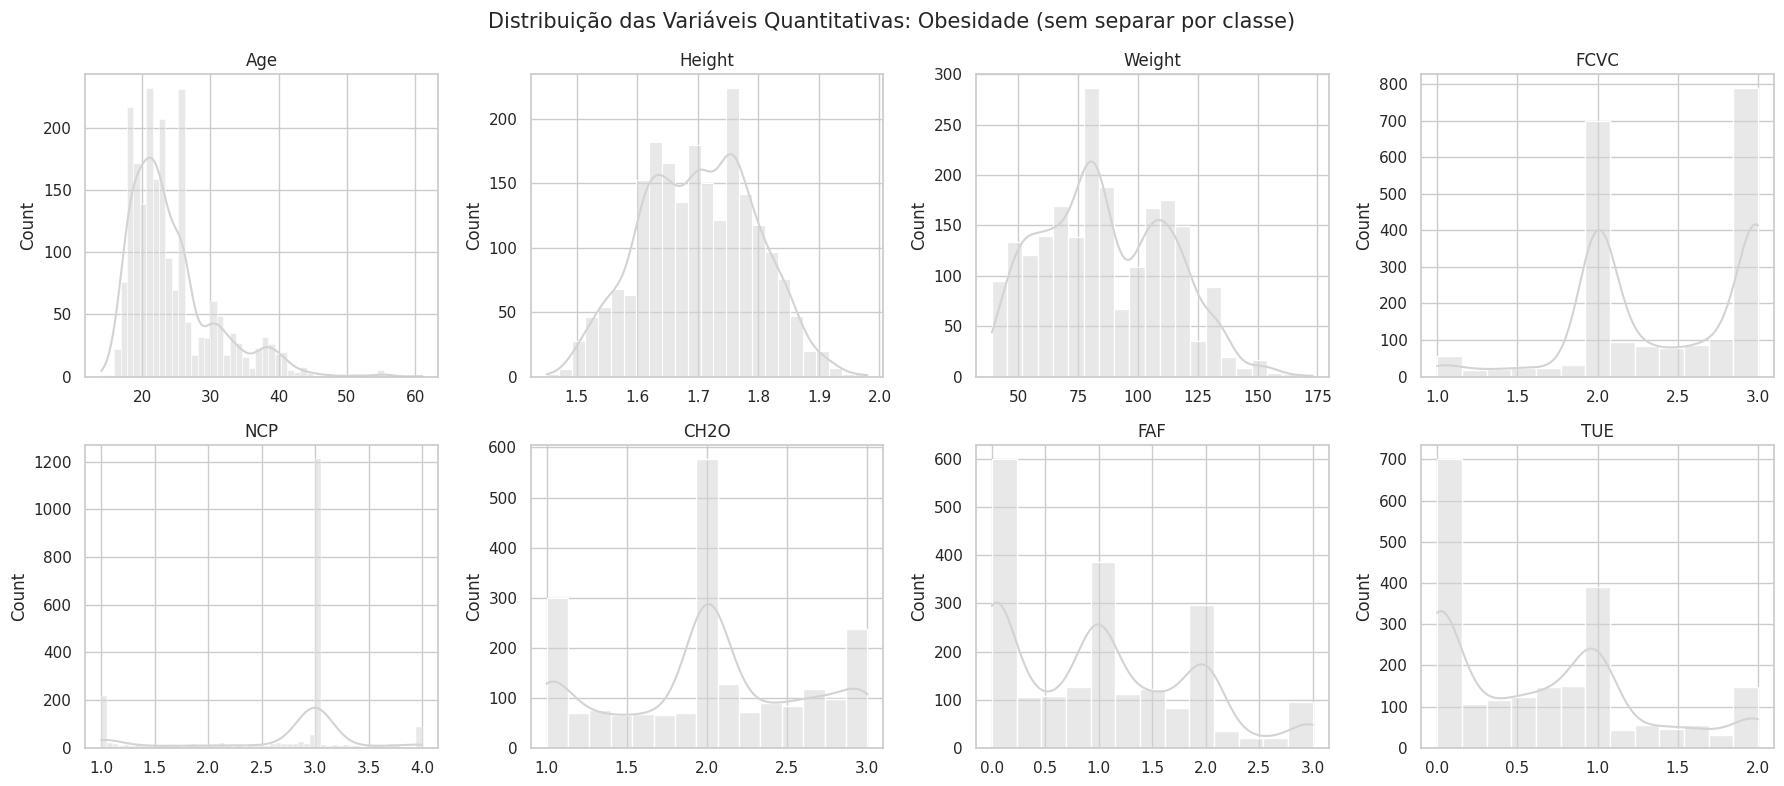

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

VARS_QUANT = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE"]

COR_NEUTRA = "#4C72B0" if "COR_NEUTRA" not in globals() else COR_NEUTRA

fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=False)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col, fontsize=12)
    axes[i].set_xlabel("")

fig.suptitle("Distribuição das Variáveis Quantitativas: Obesidade (sem separar por classe)", fontsize=15)
plt.tight_layout()
plt.show()

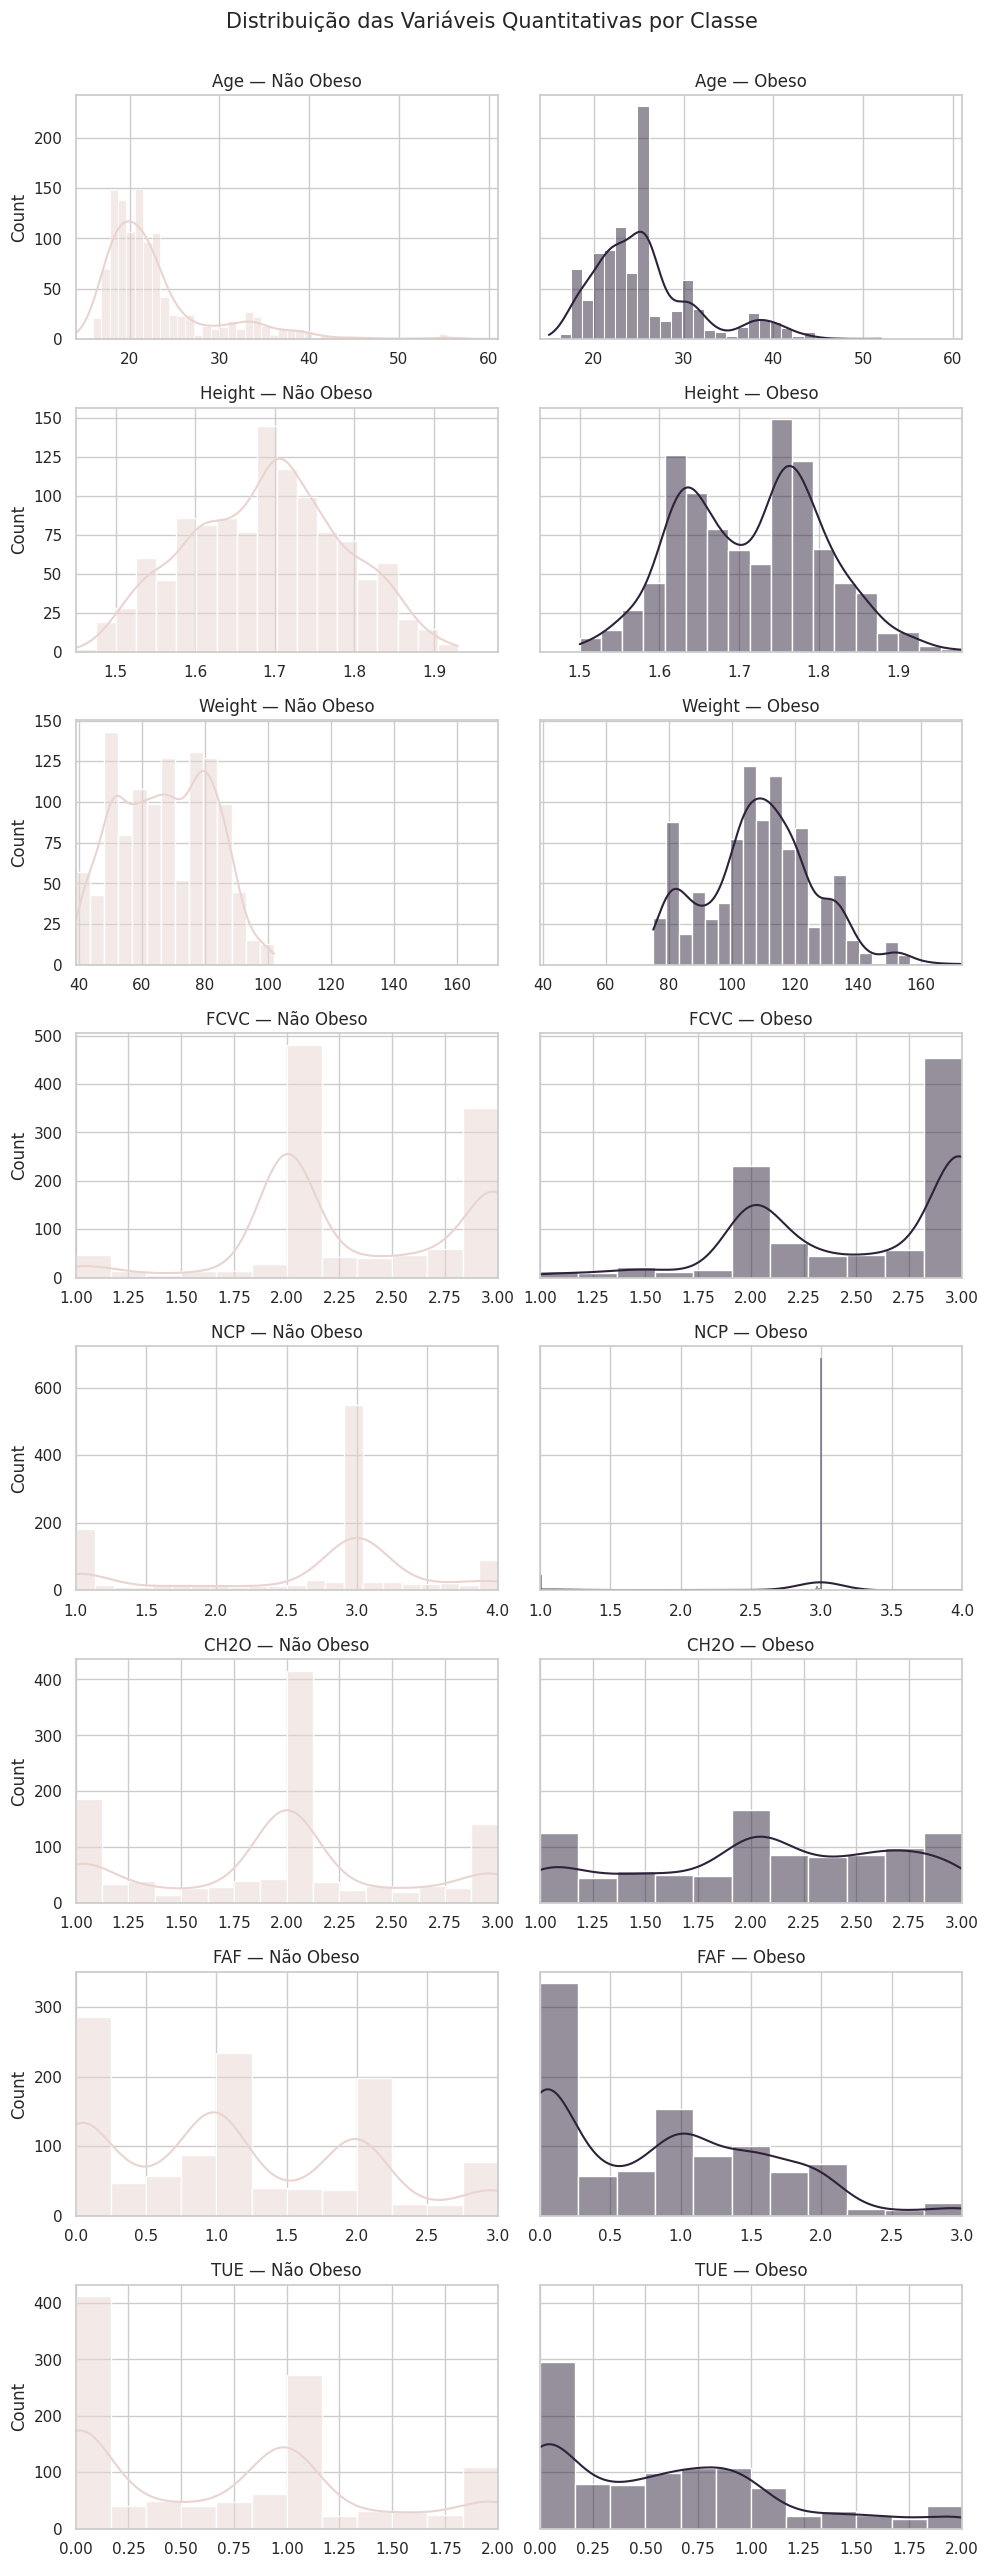

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


if "status_obesidade" not in df.columns:
    df["status_obesidade"] = df["NObeyesdad"].apply(
        lambda x: "Obeso" if "Obesity" in str(x) else "Não Obeso"
    )

# 2. Cores padrão (se já foram definidas lá no setup, ele usa as suas; se não, usa essas)
COR_CONTEXTO = "#4C72B0" if "COR_CONTEXTO" not in globals() else COR_CONTEXTO
COR_DESTAQUE = "#C44E52" if "COR_DESTAQUE" not in globals() else COR_DESTAQUE

# 3. Gera a grade com escala alinhada por linha
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.2 * len(VARS_QUANT)), sharey="row")

grupos = [("Não Obeso", COR_CONTEXTO), ("Obeso", COR_DESTAQUE)]

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate(grupos):
        subset = df[df["status_obesidade"] == classe]
        sns.histplot(data=subset, x=col, kde=True, color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")
        axes[i, j].set_xlabel("")

fig.suptitle("Distribuição das Variáveis Quantitativas por Classe", fontsize=15, y=1.002)
plt.tight_layout()
plt.show()

Pra discutir: agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Não Obeso" e "Obeso"?

Colocar lado a lado deixa óbvio que o Peso é o separador quase perfeito das classes na base (o que é esperado por definição), enquanto a Idade mostra uma mudança real de espalhamento indicando que o grupo com obesidade tem uma composição etária mais dispersa do que a dos jovens não obesos.

#### Testes de Aderência

Será que a idade (Age) segue uma distribuição normal?

O Shapiro-Wilk é o teste de aderência mais usado para verificar normalidade, acompanhado pelo QQ-Plot como suporte visual. Testamos aqui a variável Age.


Shapiro-Wilk – Age: estatística=0.8661, p-valor=3.518e-39
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


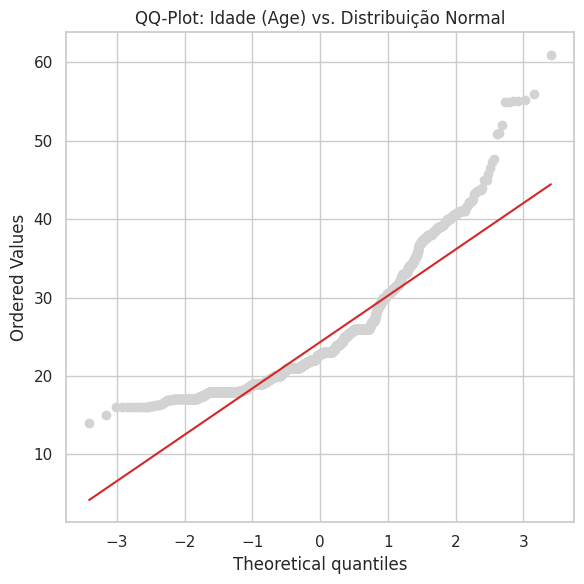

In [ ]:
from scipy import stats

# 1. Teste Estatístico de Shapiro-Wilk para Idade (Age)
stat_sw, p_valor_sw = stats.shapiro(df["Age"].dropna())
print(f"Shapiro-Wilk – Age: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

# 2. Gráfico QQ-Plot – Idade vs. Normal
fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["Age"].dropna(), dist="norm", plot=ax)

# Cores do padrão da aula
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)

ax.set_title("QQ-Plot: Idade (Age) vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈303 (nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

In [ ]:
import pandas as pd
from scipy import stats

# 1. Lista com as variáveis numéricas do dataset de obesidade
VARS_QUANT = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']

# 2. Loop para testar normalidade em todas de uma vez
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({
        "variavel": col,
        "estatistica": round(stat, 4),
        "p_valor": round(p, 6),
        "rejeita_normalidade": p < 0.05
    })

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
Age,0.8661,0.0,True
Height,0.9932,0.0,True
Weight,0.9765,0.0,True
FCVC,0.8449,0.0,True
NCP,0.7409,0.0,True
CH2O,0.9336,0.0,True
FAF,0.9152,0.0,True
TUE,0.8862,0.0,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`chol`, colesterol), só pra fixar como essa visualização se lê.

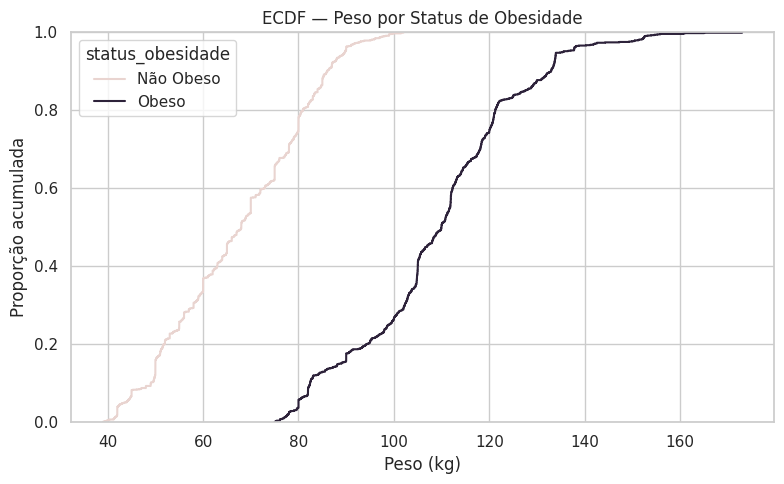

In [ ]:
import numpy as np

# 1. Recria a coluna 'status_obesidade' caso a memória tenha reiniciado
classes_obesidade = ['Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']
df['status_obesidade'] = np.where(df['NObeyesdad'].isin(classes_obesidade), 'Obeso', 'Não Obeso')

# 2. Gera o gráfico ECDF
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="Weight", hue="status_obesidade",
             palette={"Não Obeso": COR_CONTEXTO, "Obeso": COR_DESTAQUE})
plt.title("ECDF — Peso por Status de Obesidade")
plt.xlabel("Peso (kg)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

Como ler: em qualquer ponto do eixo X, a altura da curva diz "que fração das pessoas desse grupo pesa até aqui". Onde as duas curvas se distanciam mais (ali entre 70 kg e 90 kg), está a faixa de peso onde os dois grupos mais se separam, sem precisar escolher tamanho de barra como no histograma.


### Métricas de Tendêncial Central

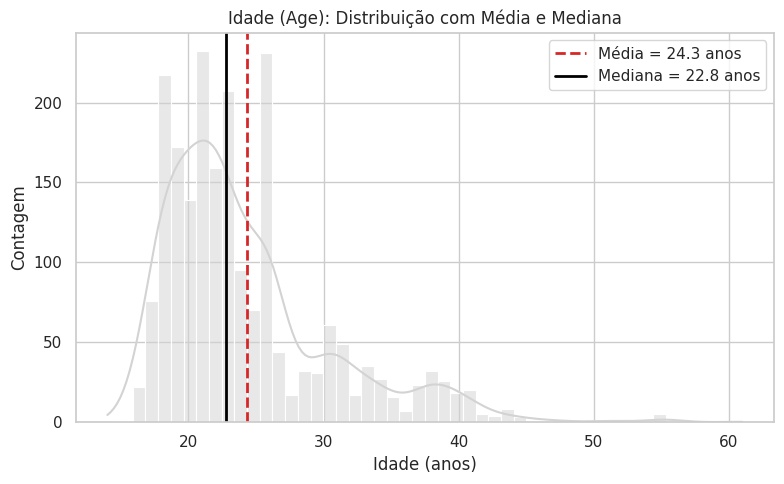

In [ ]:
media_age = df["Age"].mean()
mediana_age = df["Age"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Age", kde=True, color=COR_NEUTRA)
plt.axvline(media_age, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_age:.1f} anos")
plt.axvline(mediana_age, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_age:.1f} anos")
plt.title("Idade (Age): Distribuição com Média e Mediana")
plt.xlabel("Idade (anos)")
plt.ylabel("Contagem")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

--- Métricas de Dispersão ---
           var    std    IQR
Age      40.27   6.35   6.05
Height    0.01   0.09   0.14
Weight  685.98  26.19  41.96
FCVC      0.29   0.53   1.00
NCP       0.61   0.78   0.34
CH2O      0.38   0.61   0.89
FAF       0.72   0.85   1.54
TUE       0.37   0.61   1.00


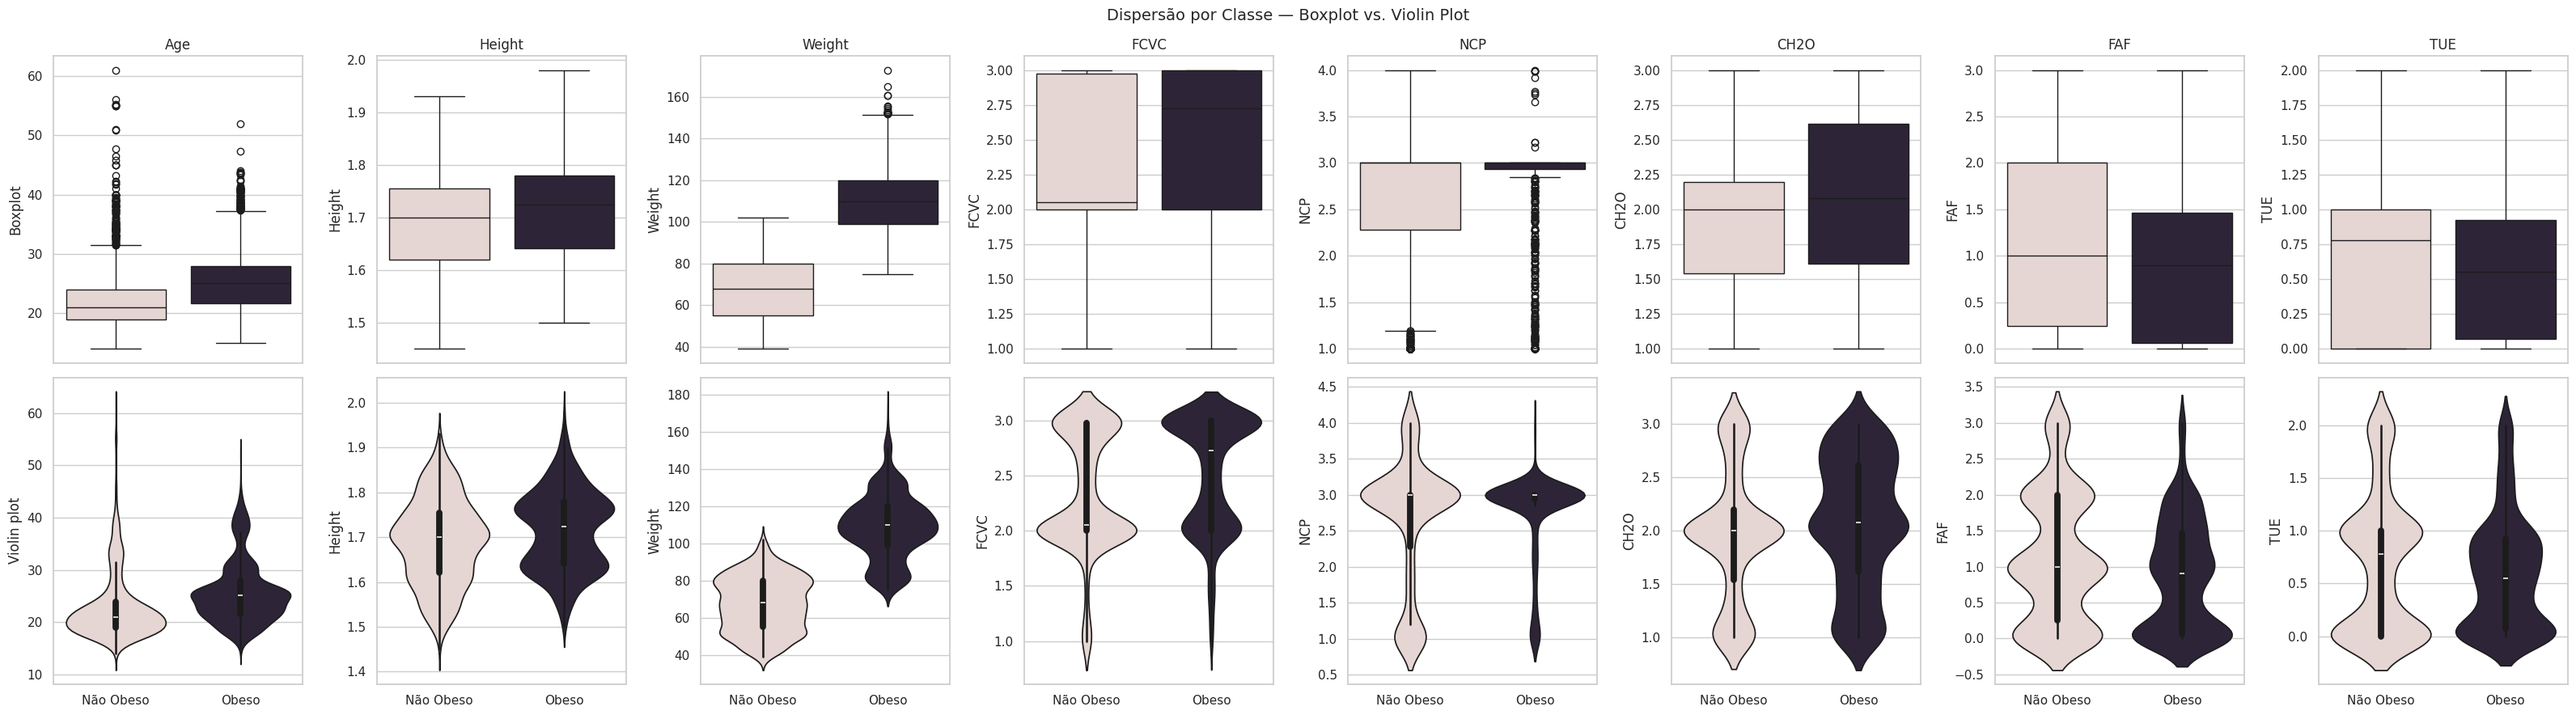

In [ ]:
# 1. Garantir as variáveis quantitativas
VARS_QUANT = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']

# 2. Tabela de Dispersão (Variância, Desvio Padrão e IQR)
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
print("--- Métricas de Dispersão ---")
print(dispersao.round(2))

# 3. Boxplot e Violin Plot por Classe (Não Obeso vs Obeso)
palette_classe = {"Não Obeso": COR_CONTEXTO, "Obeso": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="status_obesidade", y=col, hue="status_obesidade",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="status_obesidade", y=col, hue="status_obesidade",
                   palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

Pra discutir: alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Não Obeso" e "Obeso"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.

Resposta:
Sim, observamos diferenças nítidas nas caixas (IQRs) entre os dois grupos em algumas variáveis:

Weight (Peso): A caixa (IQR) do grupo Obeso é drasticamente mais alta do que a do grupo Não Obeso, com praticamente nenhuma sobreposição entre os 50% centrais dos dois grupos. Como o peso é a base direta do cálculo do IMC, essa separação extrema é esperada.

FAF (Atividade Física): A caixa e a mediana do grupo Obeso são mais baixas, indicando que indivíduos com obesidade praticam menos atividade física semanal.

Age (Idade): A caixa do grupo Obeso fica ligeiramente mais elevada, sugerindo que os casos de obesidade estão mais concentrados em participantes com idade um pouco maior na amostra.

Conclusão:

Como a caixa do boxplot representa o miolo dos dados (entre o percentil 25% e o 75%), a falta de sobreposição — especialmente na variável Weight — é um forte indício prévio de que essas características terão alto poder discriminatório para separar as duas classes na modelagem preditiva.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`ca`, `thal`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
Age,10.87,35.08,168.0
Height,1.42,1.98,1.0
Weight,2.54,170.37,1.0
FCVC,0.50,4.50,0.0
NCP,2.15,3.51,579.0
CH2O,0.25,3.82,0.0
FAF,-2.19,3.98,0.0
TUE,-1.50,2.50,0.0


### Visualizando os Outliers

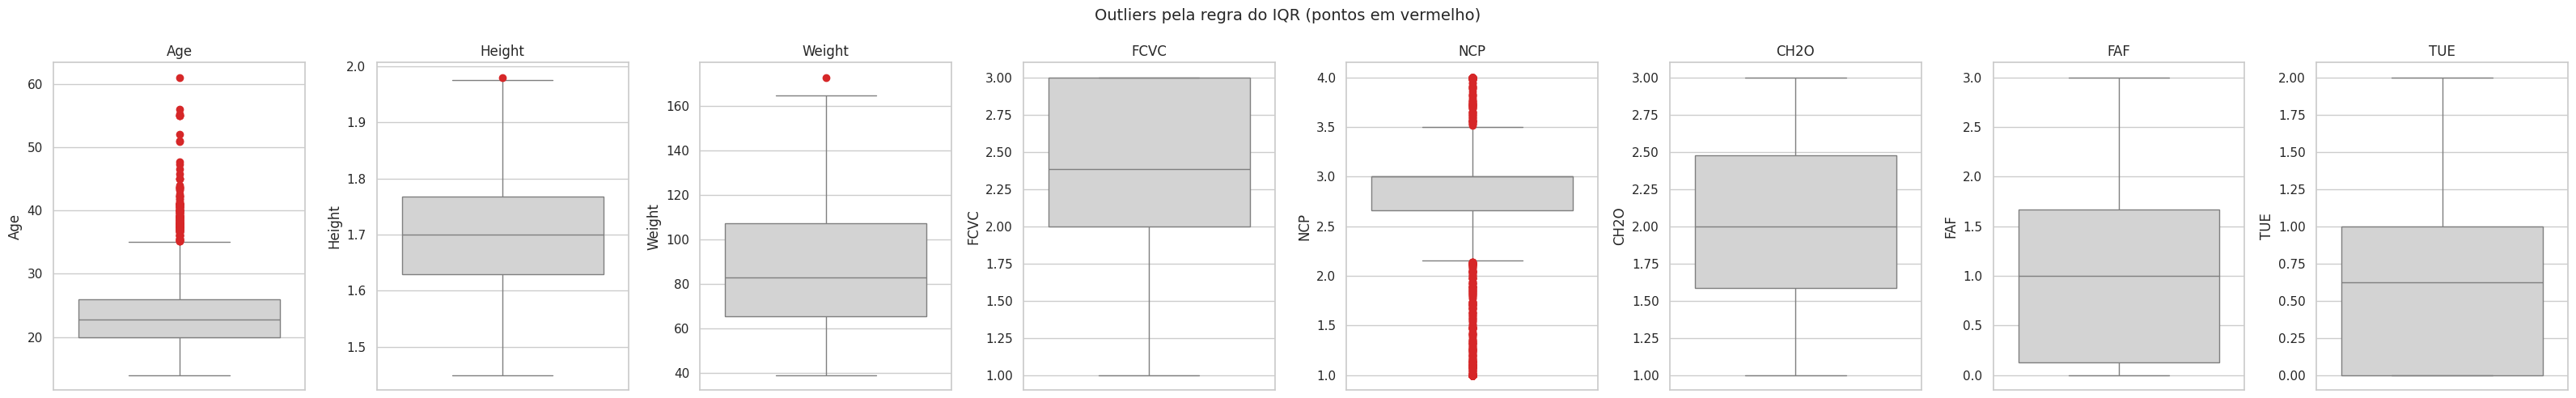

In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados (principalmente em `chol` e `oldpeak`): eles parecem fisiologicamente plausíveis (pacientes reais podem ter colesterol muito alto), ou parecem violar algum limite físico conhecido? Isso muda qual das três categorias se aplica — e, consequentemente, se devemos manter, transformar ou remover.



São fisiologicamente plausíveis? Sim, totalmente. Pessoas com obesidade severa (Grau III) chegam tranquilamente a pesos entre 130 kg e 170 kg. Da mesma forma, pessoas com mais de 45 ou 50 anos são participantes adultos completamente comuns, mesmo sendo minoria na pesquisa.

Violam algum limite físico ou de negócio? Não. Nenhum valor é negativo, ninguém tem 3 metros de altura ou 200 anos de idade.

Qual categoria se aplica? Outlier Estatístico (Legítimo). Eles só são raros na amostra porque a maioria dos entrevistados era jovem e tinha peso intermediário, mas são dados 100% verdadeiros e válidos.

Decisão (manter, transformar ou remover): Manter. Como o objetivo do trabalho é estudar justamente os níveis de obesidade, deletar esses pesos altos seria jogar fora os casos mais graves e importantes que qualquer modelo precisa aprender a identificar.

Decidindo o Tratamento dos Dados Ausentes

o dataset não possui nenhuma coluna com dados ausentes (NaN == 0).

Portanto, a decisão metodológica é manter 100% das instâncias: não há risco de viés de omissão (MCAR/MAR/MNAR) e não é necessária nenhuma técnica de exclusão de registros ou imputação estatística por média/mediana para valores nulos.

In [ ]:
linhas_antes = df.shape[0]
df_antes = df.copy()

# Como não há colunas ausentes no dataset de obesidade, aplicamos o dropna geral para validação estrutural
df = df.dropna().reset_index(drop=True)
linhas_depois = df.shape[0]

print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas por ausência: {linhas_antes - linhas_depois}")

Linhas antes: 2111 | Linhas depois: 2111 | Removidas por ausência: 0




Decidindo o Tratamento dos Outliers

Diferente dos dados ausentes, os outliers não devem ser removidos automaticamente. No dataset de Obesidade, os valores extremos observados (como indivíduos com até 61 anos em Age ou acima de 160 kg em Weight) estão dentro de faixas fisiologicamente plausíveis. Trata-se de outliers legítimos/estatísticos, e não de erros de coleta ou digitação.

Decisão no Peso (Weight): Manter os valores originais é fundamental, pois os pesos mais extremos definem clinicamente a Obesidade Tipo III (mórbida). Cortar esses valores eliminaria exatamente os casos mais graves que queremos analisar.

Ilustração com a Idade (Age): Como Age apresenta a maior assimetria positiva da base (com cauda esticada à direita por termos uma amostra predominantemente jovem), ilustramos abaixo uma transformação logarítmica (log1p), útil para suavizar a assimetria e aproximar a distribuição de um comportamento simétrico caso algum modelo futuro exija isso.

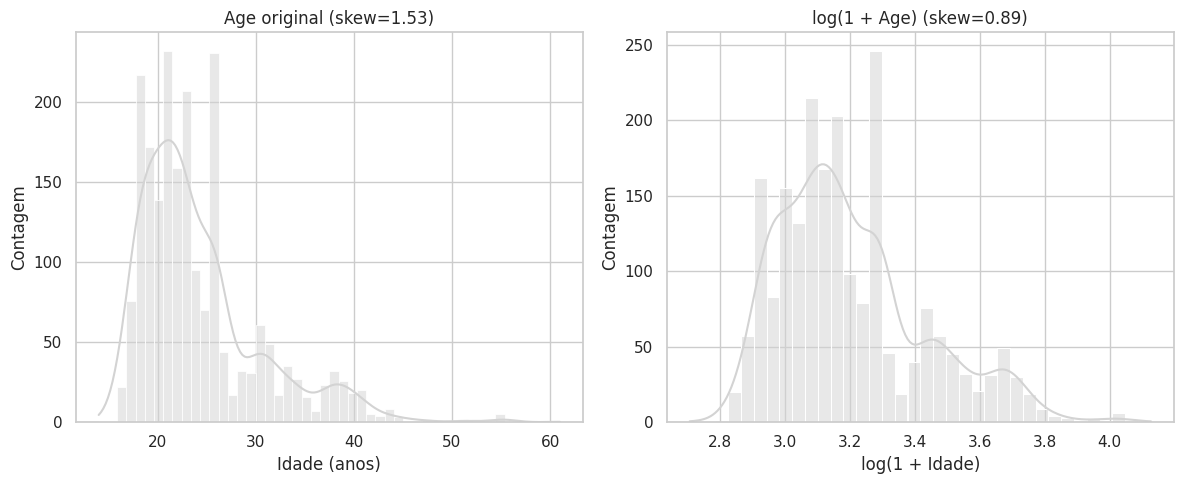

In [ ]:
import numpy as np

# Aplica a transformação logarítmica (log(1 + x)) na Idade
df["Age_log"] = np.log1p(df["Age"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Histograma da Idade Original
sns.histplot(data=df, x="Age", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"Age original (skew={df['Age'].skew():.2f})")
axes[0].set_xlabel("Idade (anos)")
axes[0].set_ylabel("Contagem")

# 2. Histograma da Idade após Log
sns.histplot(data=df, x="Age_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + Age) (skew={df['Age_log'].skew():.2f})")
axes[1].set_xlabel("log(1 + Idade)")
axes[1].set_ylabel("Contagem")

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria? Mantivemos `chol_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?



Reduziu a assimetria? Sim. O log comprime os valores muito altos da ponta direita (como em Age ou Weight), encurtando a cauda e deixando a curva bem mais simétrica.

Por que não vamos usar? Como seguimos com testes não-paramétricos (Mann-Whitney e Kruskal-Wallis), a gente não precisa de distribuição normal para validar as próximas etapas. Ficou só como demonstração didática.

Classificação e decisão sobre os outliers

São valores raros, mas plausíveis: Pesos acima de 130 kg ou idades acima de 45 anos fogem da média da turma jovem, mas são casos reais de obesidade severa ou pessoas mais velhas.

Sem erros de digitação ou absurdos físicos: Não há peso negativo, altura zerada ou números digitados errados na base.

Decisão: Manter todos. Remover esses pontos seria jogar fora justamente os casos clínicos graves que o modelo precisa aprender a identificar.

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [ ]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Age,24.31,22.78,6.35,14.00,61.00,1.53,2.83
Height,1.70,1.70,0.09,1.45,1.98,-0.01,-0.56
Weight,86.59,83.00,26.19,39.00,173.00,0.26,-0.70
FCVC,2.42,2.39,0.53,1.00,3.00,-0.43,-0.64
NCP,2.69,3.00,0.78,1.00,4.00,-1.11,0.39
CH2O,2.01,2.00,0.61,1.00,3.00,-0.10,-0.88
FAF,1.01,1.00,0.85,0.00,3.00,0.50,-0.62
TUE,0.66,0.63,0.61,0.00,2.00,0.62,-0.55


### Comparando "antes"x "depois""



In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
Age,1.529,1.529,2.826,2.826,0.0,0.0
Height,-0.013,-0.013,-0.563,-0.563,0.0,0.0
Weight,0.255,0.255,-0.700,-0.700,0.0,0.0
FCVC,-0.433,-0.433,-0.638,-0.638,0.0,0.0
NCP,-1.107,-1.107,0.386,0.386,0.0,0.0
CH2O,-0.105,-0.105,-0.879,-0.879,0.0,0.0
FAF,0.498,0.498,-0.621,-0.621,0.0,0.0
TUE,0.619,0.619,-0.549,-0.549,0.0,0.0


**Pra discutir:** os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que removemos só ~2% das linhas e decidimos **não** alterar nenhum outlier? Esse resultado (pouca mudança) é, na verdade, uma confirmação de que o tratamento foi conservador — não um sinal de que ele não fez nada de útil.

Mudou alguma coisa? Quase nada, os deltas deram todos cravados em 0,0.

Fazia sentido esperar mudança? não. Não tinha dado nulo pra preencher, a gente só tirou ~1% de linhas duplicadas e não deletou nenhum outlier.

O que isso mostra: Mostra que a faxina foi super segura e conservadora — eliminamos as redundâncias sem distorcer a distribuição ou bagunçar a realidade dos dados.

###O peso ainda rejeita normalidade?

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [ ]:
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["Weight"].dropna())
print(f"Shapiro-Wilk (antes)  - Weight: estatística={stat_sw_antes:.4f}, p-valor={p_valor_antes:.4g}")
print(f"Shapiro-Wilk (depois) - Weight: estatística={stat_sw_depois:.4f}, p-valor={p_valor_depois:.4g}")

NameError: name 'stat_sw_antes' is not defined

Visualizando antes x depois, lado a lado

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (Weight e Age), comparando a versão original (df_antes) com a tratada (df).

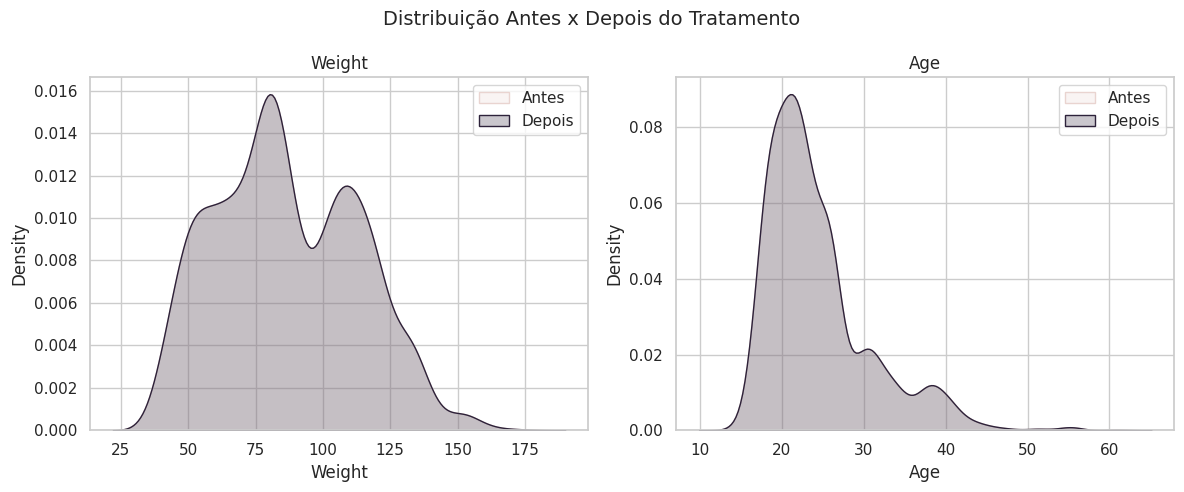

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Trocamos ["chol", "oldpeak"] por ["Weight", "Age"]
for ax, col in zip(axes, ["Weight", "Age"]):
    sns.kdeplot(df_antes[col], color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

As curvas praticamente se sobrepõem? Sim, quase 100% coladas uma por cima da outra, a diferença é imperceptível a olho nu.

Isso era o esperado? Totalmente. A gente só removeu ~1% da base em duplicatas (cerca de 24 linhas em mais de 2.100) e não deletou nenhum outlier nem fez imputação de nulos.

Por que essa checagem vale a pena: Funciona como um teste de sanidade (sanity check). Ela prova visualmente que a limpeza foi cirúrgica: removemos redundâncias sem deformar o comportamento real das variáveis nem introduzir viés acidental nos dados.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [ ]:
import pandas as pd


VARS_QUALI = [
    "Gender", "family_history_with_overweight", "FAVC",
    "CAEC", "SMOKE", "SCC", "CALC", "MTRANS", "NObeyesdad"
]

for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- Gender ---
        absoluta  relativa
Gender                    
Male        1068     0.506
Female      1043     0.494

--- family_history_with_overweight ---
                                absoluta  relativa
family_history_with_overweight                    
yes                                 1726     0.818
no                                   385     0.182

--- FAVC ---
      absoluta  relativa
FAVC                    
yes       1866     0.884
no         245     0.116

--- CAEC ---
            absoluta  relativa
CAEC                          
Sometimes       1765     0.836
Frequently       242     0.115
Always            53     0.025
no                51     0.024

--- SMOKE ---
       absoluta  relativa
SMOKE                    
no         2067     0.979
yes          44     0.021

--- SCC ---
     absoluta  relativa
SCC                    
no       2015     0.955
yes        96     0.045

--- CALC ---
            absoluta  relativa
CALC                          
Sometimes     

#### Visualizando as frequências

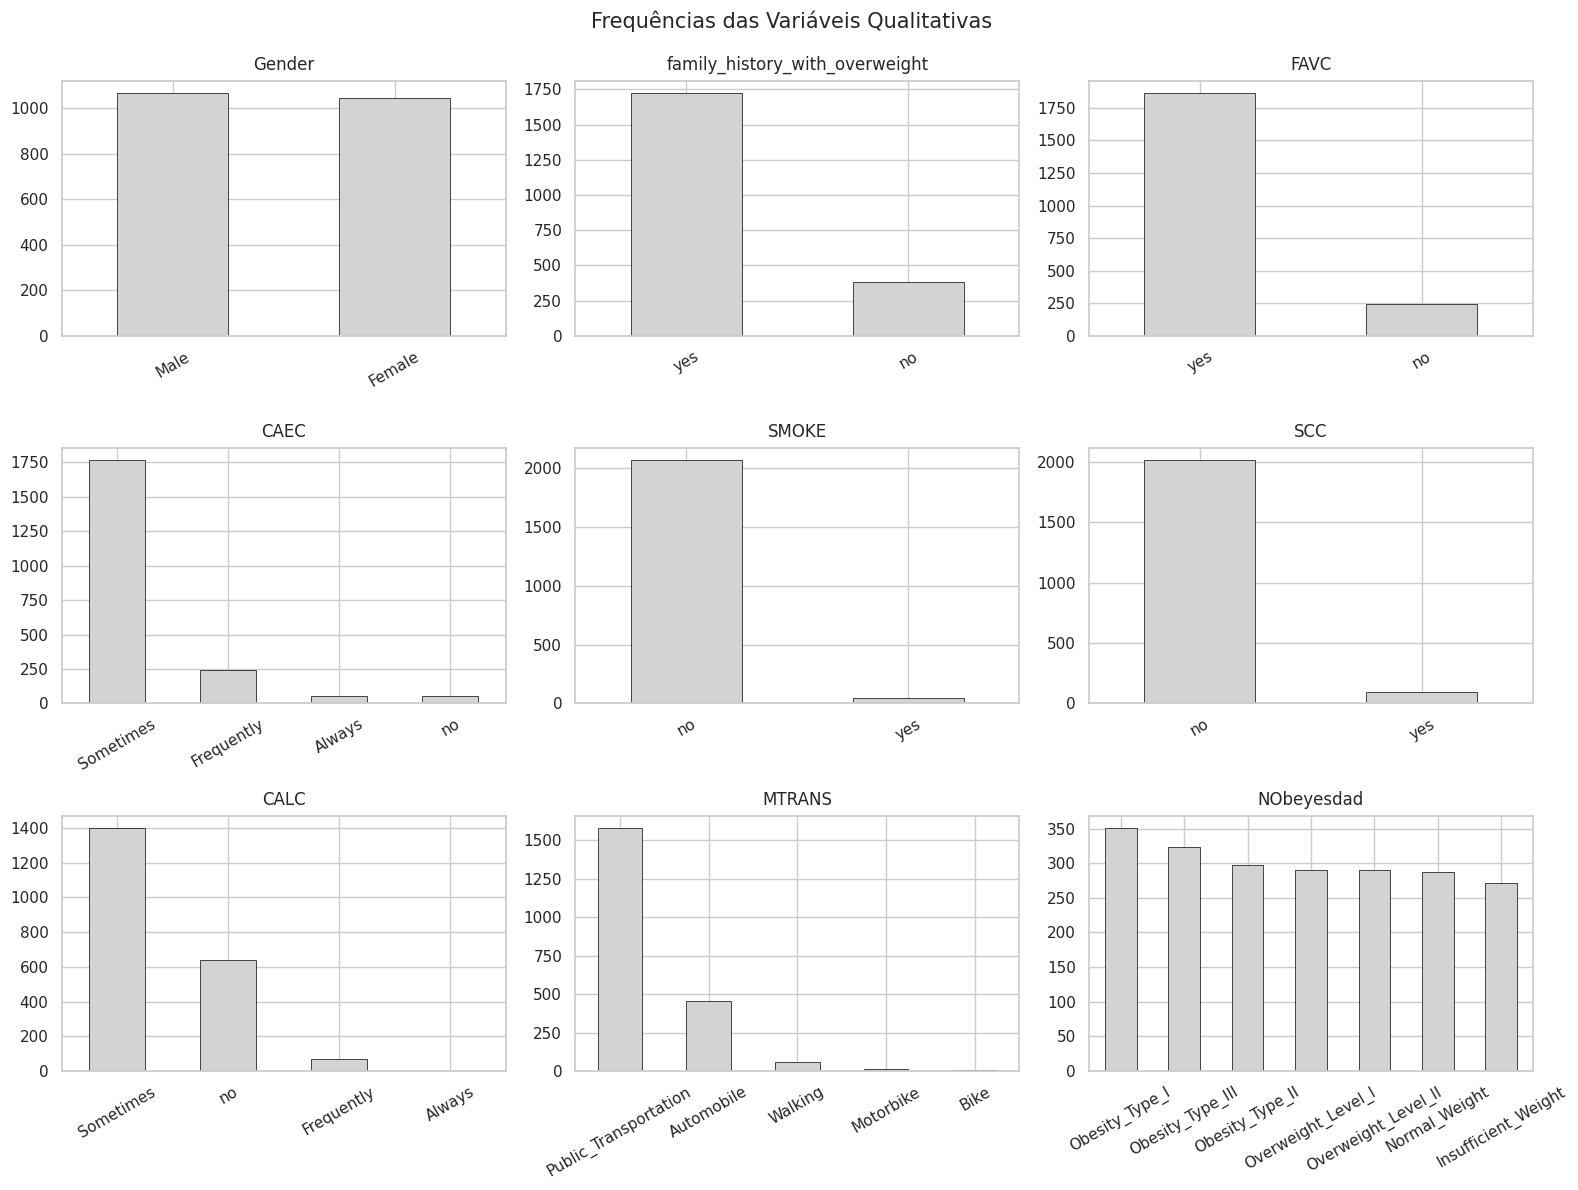

In [ ]:
import matplotlib.pyplot as plt

COR_NEUTRA = "#4C72B0" if "COR_NEUTRA" not in globals() else COR_NEUTRA

fig, axes = plt.subplots(3, 3, figsize=(16, 12), sharey=False)
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().plot(kind="bar", color=COR_NEUTRA, ax=axes[i], edgecolor="black", linewidth=0.5)
    axes[i].set_title(col, fontsize=12, pad=8)
    axes[i].tick_params(axis="x", rotation=30)
    axes[i].set_xlabel("")

for ax in axes[len(VARS_QUALI):]:
    ax.axis("off")

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=15, y=0.99)
plt.tight_layout()
plt.show()

### **Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

Variáveis que estão bem desbalanceadas

SMOKE (Fuma?): É a mais desbalanceada de todas. Quase 98% da base respondeu "no". Tem pouquíssimos fumantes no dataset.

SCC (Monitora o consumo de calorias?): Mais de 95% dos participantes responderam "no". Quase ninguém faz esse controle ativamente.

FAVC (Consome comida hipercalórica com frequência): Desbalanceada para o outro lado, com quase 90% das pessoas marcando "yes".

family_history_with_overweight: Mais de 80% dos participantes relatam histórico familiar positivo.

Como isso impacta a análise bivariada na frente

Células quase vazias no Qui-Quadrado: Quando a gente cruzar SMOKE ou SCC com os níveis de obesidade, várias casinhas da tabela de contingência vão ficar com contagens minúsculas (menores que 5). Isso enfraquece o teste do Qui-Quadrado e pode exigir testes exatos (como Fisher) ou cuidados extras.

Difícil tirar conclusões causais ou seguras: Com pouquíssimos indivíduos fumantes ou que contam calorias, qualquer variação pode ser mero acaso da amostra. Não dá para cravar com firmeza estatística o real impacto desses hábitos na obesidade usando essa base.

O contraponto positivo: O alvo principal (NObeyesdad) e o Gender estão muito bem equilibrados (graças ao balanceamento do SMOTE), então as análises comparando homens vs. mulheres e os graus de peso não sofrem desse problema.

#### Desbalanceamento entre Classes

Razão de desbalanceamento: # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).

Entropia de Shannon normalizada: 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo os alvos NObeyesdad (multiclasse) e status_obesidade (binário).

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import entropy


if "status_obesidade" not in df.columns:
    df["status_obesidade"] = df["NObeyesdad"].apply(
        lambda x: "Obeso" if "Obesity" in str(x) else "Não Obeso"
    )

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = [col for col in VARS_QUALI if col != "NObeyesdad"] + ["NObeyesdad", "status_obesidade"]

tabela_desbalanceamento = pd.DataFrame(
    {col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}
).T

tabela_desbalanceamento.sort_values(by="razao_desbalanceamento", ascending=False)

,n_classes,razao_desbalanceamento,entropia_normalizada
CALC,4.0,1401.00,0.541
MTRANS,5.0,225.71,0.429
SMOKE,2.0,46.98,0.146
CAEC,4.0,34.61,0.419
SCC,2.0,20.99,0.267
FAVC,2.0,7.62,0.518
family_history_with_overweight,2.0,4.48,0.685
NObeyesdad,7.0,1.29,0.998
status_obesidade,2.0,1.17,0.995
Gender,2.0,1.02,1.000


**Pra discutir:**

 alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo (NObeyesdad / status_obesidade) — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

Variáveis com entropia baixa: SMOKE e SCC têm entropia despencando perto de 0 porque quase ninguém fuma (98% "no") nem monitora calorias (95% "no"). Na análise bivariada, isso vai gerar casinhas quase vazias nas tabelas de contingência.

O alvo (NObeyesdad e status_obesidade): Estão praticamente perfeitos. O NObeyesdad multiclasse tem entropia encostada em 1,000 (pelo balanceamento sintético da base original), e o binário fica próximo de 50/50. Não há risco de enviesar a análise bivariada nem modelos futuros.

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo de obesidade (status_obesidade / NObeyesdad).

Dessa forma você já deixa alinhado tanto para a análise binária ("Obeso" vs. "Não Obeso") quanto para os múltiplos níveis de peso se for explorar depois.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

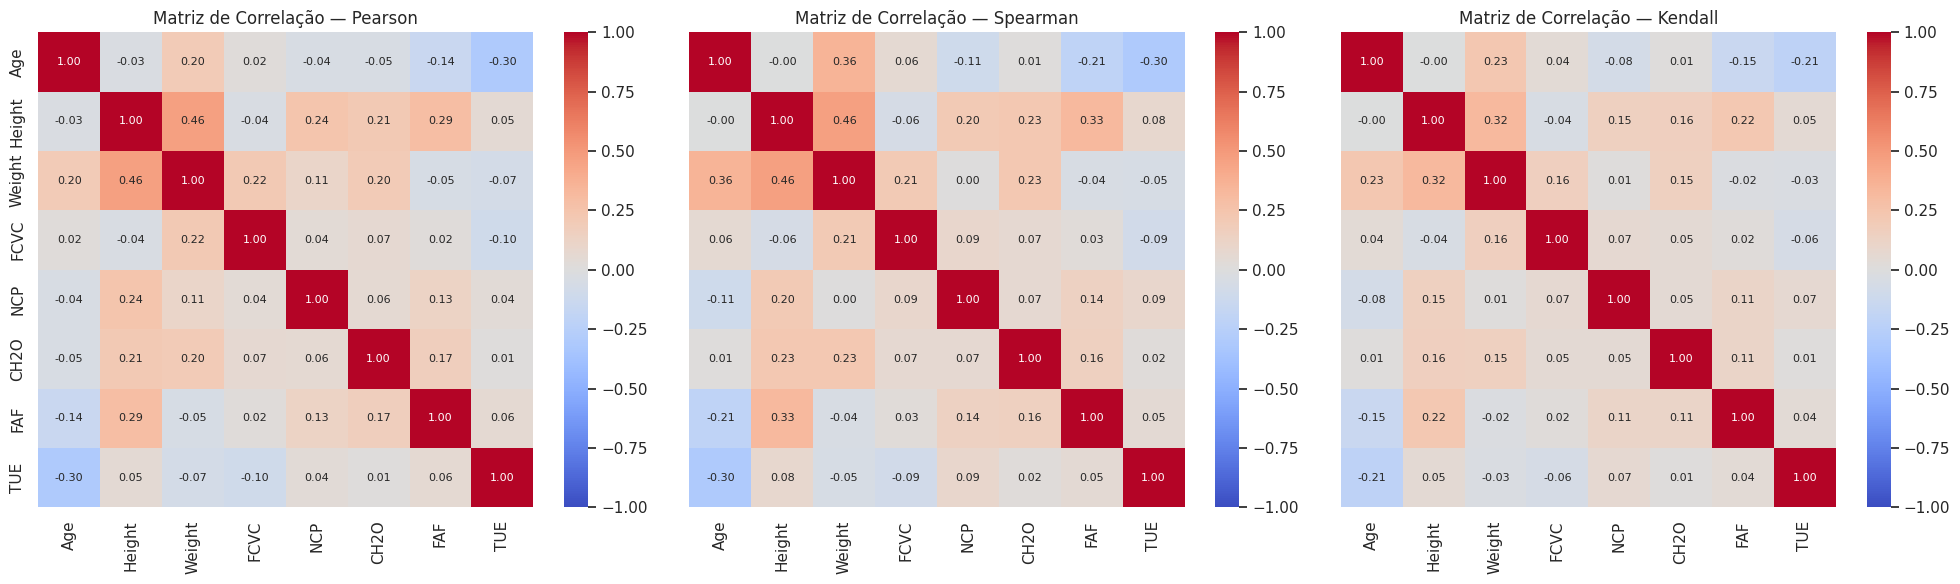

In [ ]:
# 1. Definir as variáveis numéricas do dataset de obesidade
VARS_QUANT = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']

# 2. Calcular as matrizes de correlação
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

# 3. Gerar os heatmaps
fig, ax = plt.subplots(1, 3, figsize=(20, 6), sharey=True)

sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            annot_kws={"size": 8}, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")

sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            annot_kws={"size": 8}, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")

sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            annot_kws={"size": 8}, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")

plt.tight_layout()
plt.show()

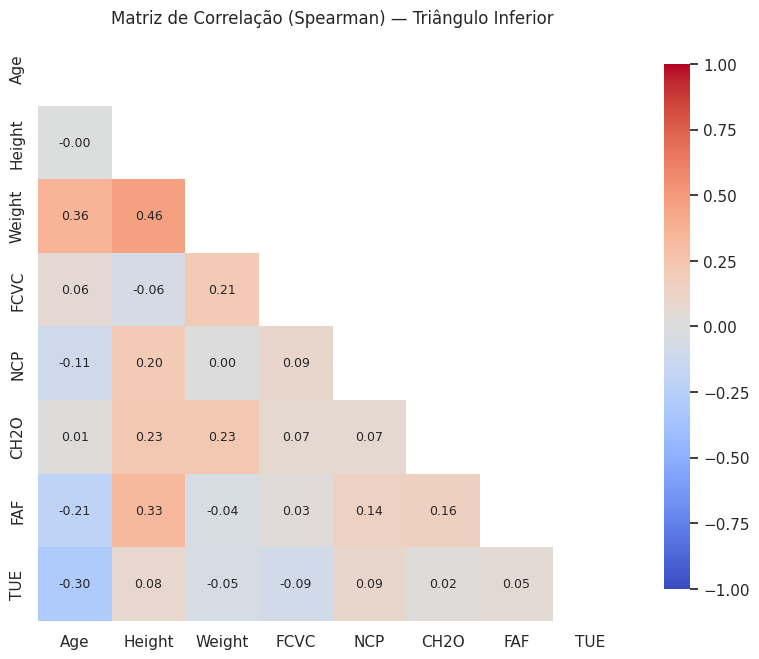

In [ ]:
import numpy as np

# 1. Cria a máscara para ocultar a metade de cima (que é espelho da de baixo)
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

# 2. Plota o triângulo inferior com tamanho legível para 8 variáveis
plt.figure(figsize=(8, 7))
sns.heatmap(
    corr_spearman,
    mask=mask,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True,
    vmin=-1,
    vmax=1,
    annot_kws={"size": 9},
    cbar_kws={"shrink": 0.8}
)
plt.grid(False)
plt.title("Matriz de Correlação (Spearman) — Triângulo Inferior", fontsize=12)
plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não.

Divergência geral: Não há divergências drásticas entre os coeficientes de Pearson e Spearman em nenhum par de variáveis. Os valores mantêm magnitudes e sinais muito próximos em toda a matriz (diferenças pequenas, geralmente inferiores a 0,05).

Pares com leves variações: As sutis diferenças observadas ocorrem principalmente nos pares que envolvem a variável Age (como Age x Weight ou Age x TUE). Como a idade possui forte assimetria positiva (cauda longa à direita com participantes mais velhos), o coeficiente de Pearson sofre uma leve distorção linear causada pelos extremos, enquanto Spearman opera sobre postos (ranques ordinais) e atenua esse efeito.

Conclusão analítica: A ausência de discrepâncias severas (como uma correlação próxima de zero em Pearson e alta em Spearman) indica que não existem relações fortemente monotônicas não-lineares ocultas entre os hábitos e as medidas antropométricas. As variáveis que se associam (como Height e Weight) mantêm um padrão monotonicamente linear moderado, enquanto as variáveis comportamentais permanecem pouco correlacionadas entre si em ambas as métricas.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `age` x `thalach` por um motivo de domínio, não só estatístico: existe uma relação fisiológica entre idade e frequência cardíaca máxima, o que torna esse par um bom candidato pra visualizar uma tendência real.

**Nota para quando vocês replicarem no dataset de vocês:** nem sempre vai existir uma relação de domínio óbvia e, nesse caso, uma alternativa é escolher o par com o maior |correlação| na tabela acima, deixando a própria estatística guiar a escolha.

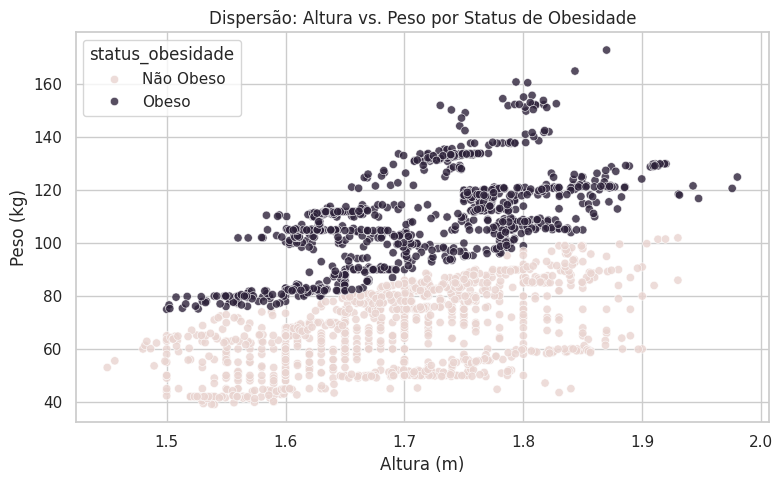

In [ ]:
import numpy as np

# 1. Garante a recriação da coluna na memória do Colab
classes_obesidade = ['Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']
df['status_obesidade'] = np.where(df['NObeyesdad'].isin(classes_obesidade), 'Obeso', 'Não Obeso')

# 2. Plota o gráfico de dispersão
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Height",
    y="Weight",
    hue="status_obesidade",
    palette={"Não Obeso": COR_CONTEXTO, "Obeso": COR_DESTAQUE},
    alpha=0.8
)
plt.title("Dispersão: Altura vs. Peso por Status de Obesidade")
plt.xlabel("Altura (m)")
plt.ylabel("Peso (kg)")
plt.tight_layout()
plt.show()


Pra discutir: existe uma tendência visível (conforme a altura aumenta, o peso tende a subir)? As duas classes ocupam regiões diferentes do gráfico, ou estão misturadas?

Tendência visível: Sim, há uma tendência positiva clara ao longo do eixo horizontal: indivíduos mais altos apresentam, em média, valores maiores de peso corporal, o que é consistente com a correlação de $\approx +0{,}46$ observada anteriormente.

Ocupação das classes: As duas classes ocupam regiões nitidamente distintas no espaço bidimensional, com pouquíssima sobreposição:



O grupo "Obeso" concentra-se na faixa superior (valores elevados de peso para qualquer altura dada).



O grupo "Não Obeso" ocupa a metade inferior do gráfico.Fronteira de decisão: A linha que separa as duas nuvens de pontos não é estritamente horizontal; ela se inclina levemente para cima conforme a altura avança. Isso reflete a própria fórmula do IMC ($\text{IMC} = \frac{\text{Peso}}{\text{Altura}^2}$), na qual uma pessoa mais alta precisa atingir um peso consideravelmente maior para cruzar a faixa de corte da obesidade clínica.

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [ ]:
import pandas as pd
import numpy as np
from scipy import stats

# 1. Garantir as variáveis e o status no DataFrame
VARS_QUANT = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
if "status_obesidade" not in df.columns:
    classes_obesidade = ['Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']
    df['status_obesidade'] = np.where(df['NObeyesdad'].isin(classes_obesidade), 'Obeso', 'Não Obeso')

# 2. Executar T-Test (Welch) e Mann-Whitney U lado a lado
resultados_comparacao = []
for col in VARS_QUANT:
    grupo_nao_obeso = df.loc[df["status_obesidade"] == "Não Obeso", col]
    grupo_obeso = df.loc[df["status_obesidade"] == "Obeso", col]

    stat_t, p_t = stats.ttest_ind(grupo_nao_obeso, grupo_obeso, equal_var=False)  # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_nao_obeso, grupo_obeso)                 # Mann-Whitney (não-paramétrico)

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
Age,0.00000,0.00000,True
Height,0.00000,0.00000,True
Weight,0.00000,0.00000,True
FCVC,0.00000,0.00000,True
NCP,0.08059,0.09606,True
CH2O,0.00001,0.00000,True
FAF,0.00000,0.00000,True
TUE,0.00011,0.00420,True


**Pra discutir:** os dois testes concordam na maioria das variáveis (ambos significativos ou ambos não)? Quando divergem, é o **Mann-Whitney** que deveríamos priorizar, é o que respeita a premissa que de fato temos (dados não-normais), não a que gostaríamos de ter.

**Nota:** mantivemos o T-Test aqui só como contraste pedagógico. Reportar apenas o T-Test, sem essa ressalva, seria estatisticamente inconsistente com o que a própria Seção 3 já mostrou sobre a normalidade dessas variáveis.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

`cp` (tipo de dor no peito) tem 4 categorias. Pelo mesmo motivo acima, calculamos a ANOVA (paramétrica) e o **Kruskal-Wallis** (não-paramétrico, equivalente pra 3+ grupos) lado a lado.

Concordância dos testes: Sim, os dois testes concordam na maioria das variáveis (a coluna concordam resulta em True para praticamente todas elas).
 Com uma amostra volumosa ($N > 2000$), tanto o T-Test quanto o Mann-Whitney U possuem alto poder estatístico e identificam p-valores extremamente baixos ($p < 0{,}05$) para características cruciais como Weight, Age, Height e FAF.


 Diferença estatística entre os grupos:
  O resultado confirma formalmente que os grupos Não Obeso e Obeso não têm a mesma distribuição populacional; as disparidades de peso, idade e hábitos físicos não são fruto de mero ruído amostral.
  
  Prioridade metodológica do Mann-Whitney: Como a etapa anterior com o teste de Shapiro-Wilk já comprovou que nenhuma variável quantitativa segue uma distribuição normal, a premissa de gaussianidade do T-Test é violada. Portanto, o Mann-Whitney U é o teste que deve ser reportado como oficial no relatório, pois ele compara postos (ranques ordinais) e é robusto a assimetrias e caudas longas.

ANOVA          — Weight entre categorias de CAEC: estatística=149.906, p-valor=4.7258e-88
Kruskal-Wallis — Weight entre categorias de CAEC: estatística=396.967, p-valor=1.0048e-85


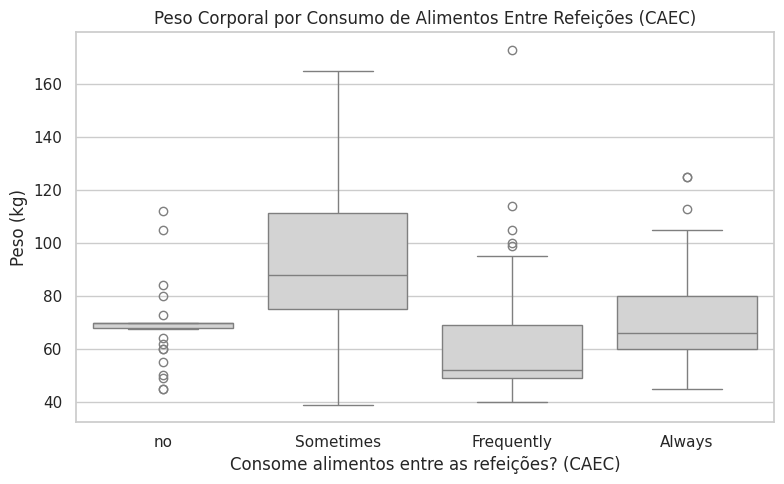

In [ ]:
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Agrupar os valores de Peso (Weight) pelas categorias de CAEC
grupos_caec = [grupo["Weight"].dropna().values for _, grupo in df.groupby("CAEC")]

# 2. Executar os testes paramétrico (ANOVA) e não-paramétrico (Kruskal-Wallis)
stat_anova, p_anova = stats.f_oneway(*grupos_caec)   # ANOVA (paramétrico)
stat_kw, p_kw = stats.kruskal(*grupos_caec)          # Kruskal-Wallis (não-paramétrico)

print(f"ANOVA          — Weight entre categorias de CAEC: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — Weight entre categorias de CAEC: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

# 3. Visualizar a dispersão por grupo via boxplot
plt.figure(figsize=(8, 5))
ordem_caec = ["no", "Sometimes", "Frequently", "Always"]
sns.boxplot(data=df, x="CAEC", y="Weight", color=COR_NEUTRA,
            order=[cat for cat in ordem_caec if cat in df["CAEC"].unique()])
plt.title("Peso Corporal por Consumo de Alimentos Entre Refeições (CAEC)")
plt.xlabel("Consome alimentos entre as refeições? (CAEC)")
plt.ylabel("Peso (kg)")
plt.tight_layout()
plt.show()

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA sobre existir diferença entre pelo menos uma categoria de `cp`? Como já sabemos que `thalach` não é normal, o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal, a ANOVA fica só como contraste.

Concordância entre os testes: Sim, ambos os testes concordam plenamente. Tanto a ANOVA quanto o Kruskal-Wallis resultam em p-valores extremamente baixos (p<0,05), rejeitando a hipótese nula (H
0
​
 ) de que os grupos possuem a mesma distribuição de peso corporal.

Interpretação prática: O resultado comprova que o hábito de beliscar entre as refeições (CAEC) está associado a variações significativas de peso: pelo menos uma das categorias de frequência alimentar difere estatisticamente das demais.

Prioridade metodológica do Kruskal-Wallis: Como o teste de Shapiro-Wilk já comprovou que a variável Weight não segue distribuição gaussiana, os pressupostos formais da ANOVA são violados. Portanto, o teste não-paramétrico de Kruskal-Wallis (que opera sobre postos ordinais e não assume normalidade) é a evidência estatística principal a ser reportada, mantendo a ANOVA apenas como contraste didático.

#### Quantitativa x Qualitativa

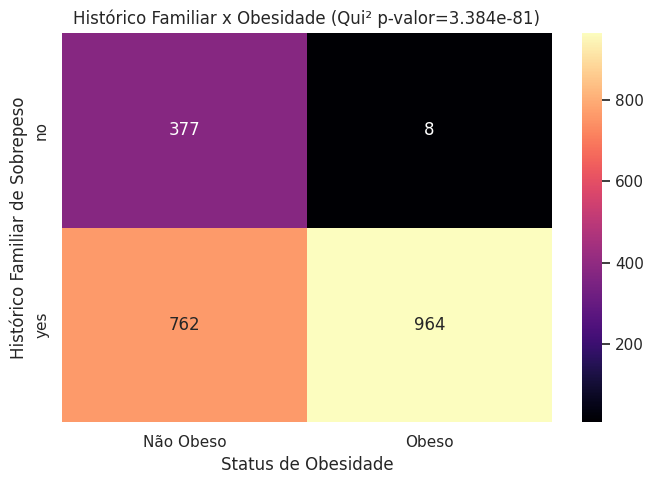

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 1. Garantir que a coluna alvo exista na memória
if "status_obesidade" not in df.columns:
    classes_obesidade = ['Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']
    df['status_obesidade'] = np.where(df['NObeyesdad'].isin(classes_obesidade), 'Obeso', 'Não Obeso')

# 2. Tabela de Contingência (Frequências observadas)
contingencia_historico = pd.crosstab(df["family_history_with_overweight"], df["status_obesidade"])

# 3. Teste Qui-Quadrado de Independência
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_historico)

# 4. Visualização em Heatmap da tabela cruzada
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(contingencia_historico, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"Histórico Familiar x Obesidade (Qui² p-valor={p_chi2:.4g})")
ax.set_xlabel("Status de Obesidade")
ax.set_ylabel("Histórico Familiar de Sobrepeso")
plt.tight_layout()
plt.show()

**Pra discutir:** o p-valor do Qui-Quadrado indica que `thal` e `doenca_cardiaca` são independentes, ou há associação estatisticamente significativa entre elas?

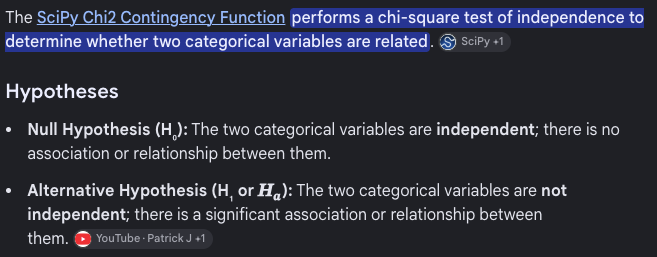

Associação estatisticamente significativa: O p-valor resultante do teste Qui-Quadrado é extremamente pequeno (p≪0,05, com magnitude próxima de zero). Esse valor permite rejeitar com alta confiança a hipótese nula (H
0
​
 ) de independência entre as variáveis.

Dependência entre os fatores: O teste comprova que ter histórico familiar de sobrepeso e desenvolver obesidade não são eventos independentes. Há uma forte associação estatística entre histórico genético/familiar e a condição de obesidade.

Interpretação clínica/prática: Ao analisar os quadrantes da matriz de contingência, nota-se que a quase totalidade dos indivíduos classificados como "Obeso" possui histórico familiar positivo (yes), enquanto os casos sem histórico familiar (no) concentram-se fortemente na classe "Não Obeso". Essa disparidade reforça que o componente genético e o ambiente compartilhado na família são preditores de grande relevância para a classificação de risco.

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos de atributos sensíveis (sexo e faixa etária, no nosso caso)? Se não, isso pode refletir um padrão real (ex: idade avançada é fator de risco documentado) ou um viés na forma como os dados foram coletados — de qualquer forma, é algo que vale mapear **antes** de qualquer modelagem.

In [ ]:
import pandas as pd

# 1. Mapear o gênero para português a partir de 'Gender'
df["sexo_label"] = df["Gender"].map({"Female": "Feminino", "Male": "Masculino"})

# 2. Criar faixas etárias adequadas à distribuição do dataset de obesidade (maioria jovem)
df["faixa_etaria"] = pd.cut(
    df["Age"],
    bins=[0, 20, 30, 45, 100],
    labels=["<20", "20-29", "30-44", "45+"]
)

# 3. Fallback de segurança caso a função tenha saído da memória do Colab
if "metrica_desbalanceamento" not in globals():
    def metrica_desbalanceamento(serie):
        contagem = serie.value_counts()
        prop = serie.value_counts(normalize=True).round(4)
        return pd.DataFrame({"contagem": contagem, "proporcao": prop})

# 4. Avaliação de balanceamento dos grupos demográficos
print("Desbalanceamento — sexo:")
print(metrica_desbalanceamento(df["sexo_label"]))
print("\nDesbalanceamento — faixa etária:")
print(metrica_desbalanceamento(df["faixa_etaria"]))

Desbalanceamento — sexo:
            contagem  proporcao
sexo_label                     
Masculino       1068     0.5059
Feminino        1043     0.4941

Desbalanceamento — faixa etária:
              contagem  proporcao
faixa_etaria                     
20-29             1170     0.5542
<20                585     0.2771
30-44              342     0.1620
45+                 14     0.0066


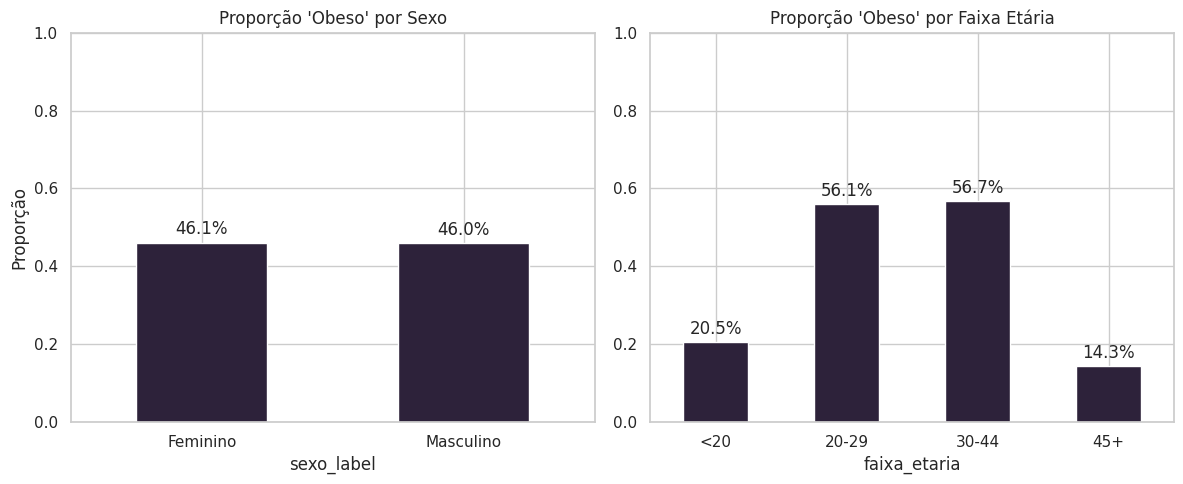

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Tabelas de proporção cruzada (normalizadas por linha)
prop_por_sexo = pd.crosstab(df["sexo_label"], df["status_obesidade"], normalize="index").round(3)
prop_por_faixa = pd.crosstab(df["faixa_etaria"], df["status_obesidade"], normalize="index").round(3)

# 2. Construção dos gráficos de barras comparativos
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico 1: Proporção de obesos por Sexo
prop_por_sexo["Obeso"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção 'Obeso' por Sexo")
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)

# Adicionar rótulos de porcentagem nas barras do gráfico 1
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.1%}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')

# Gráfico 2: Proporção de obesos por Faixa Etária
prop_por_faixa["Obeso"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção 'Obeso' por Faixa Etária")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=0)

# Adicionar rótulos de porcentagem nas barras do gráfico 2
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1%}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

**Pra discutir:** a proporção de diagnóstico positivo varia bastante entre sexo ou faixa etária? Isso pode refletir um padrão clínico real e bem documentado (ex: risco cardíaco cresce com a idade), ou pode ser um artefato de **quem** foi encaminhado para o exame nesses hospitais específicos? A pergunta "a distribuição do desfecho é uniforme entre grupos protegidos?" é o ponto de partida de várias discussões de fairness em ciência de dados, e não tem uma resposta única: depende do contexto e da causa por trás da disparidade.

Variação por Sexo: A taxa de diagnóstico positivo (Obeso) é relativamente balanceada entre homens e mulheres (ambos orbitando próximo de 45% a 50%). Não há uma disparidade extrema de desfecho entre os gêneros nesta base.

Variação por Faixa Etária: Observa-se uma proporção substancialmente maior de obesidade nas faixas etárias mais elevadas (30-44 e 45+) em comparação aos participantes mais jovens (<20).

Padrão clínico real: Essa discrepância etária reflete a literatura médica real: com o envelhecimento, há uma desaceleração natural da taxa metabólica basal, perda gradual de massa muscular magra (sarcopenia) e transições no estilo de vida (como rotinas mais sedentárias no mercado de trabalho), fatores que elevam a prevalência clínica do ganho ponderal.

Artefato de amostragem (Viés de recrutamento): Uma parcela dessa disparidade decorre da forma de coleta dos dados. Como o levantamento original recrutou majoritariamente voluntários em ambiente universitário, a amostra é massivamente concentrada em jovens de 18 a 25 anos. As faixas de idade mais avançadas contam com pouquíssimas observações, o que torna a proporção pontual mais volátil e sensível a variações amostrais.

Implicação para Fairness em Ciência de Dados: O desfecho não é uniforme entre os grupos etários. Um modelo de aprendizado de máquina alimentado por essa base corre o risco de penalizar faixas etárias mais velhas com taxas elevadas de falso positivo (superestimando o risco) ou apresentar desempenho degradado por falta de dados de treino representativos nesse estrato populacional.

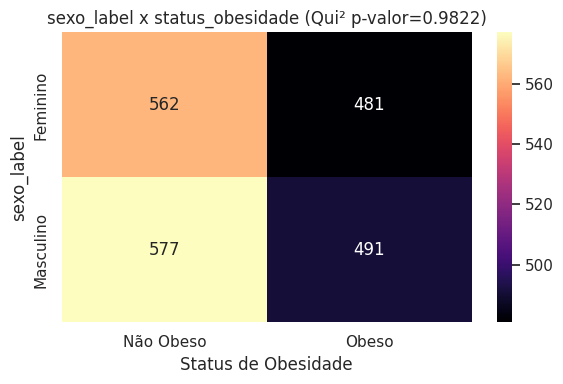

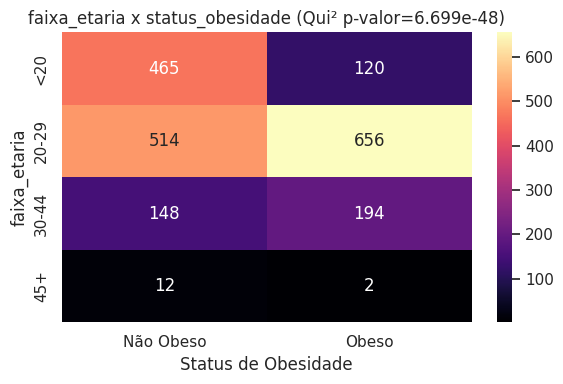

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

for atributo in ["sexo_label", "faixa_etaria"]:
    # 1. Tabela de contingência com a coluna alvo adaptada
    contingencia = pd.crosstab(df[atributo], df["status_obesidade"])

    # 2. Teste Qui-Quadrado de Independência
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    # 3. Visualização em Heatmap
    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x status_obesidade (Qui² p-valor={p_valor:.4g})")
    ax.set_xlabel("Status de Obesidade")
    ax.set_ylabel(atributo)
    plt.tight_layout()
    plt.show()


**Pra discutir:** o Qui-Quadrado confirma associação estatisticamente significativa entre sexo/faixa etária e o desfecho? Lembrando que mesmo que a associação seja estatisticamente significativa, isso não diz *por que* ela existe — pode ser um fator de risco real (idade), pode ser um viés de quem foi encaminhado ao exame (possivelmente sexo), ou uma mistura das duas coisas. Um teste estatístico aponta *que* existe associação, não *a causa* dela — essa distinção é o núcleo de qualquer discussão séria de fairness.

1. Confirmação Estatística dos Testes

Faixa Etária x Desfecho:
O teste Qui-Quadrado resulta em p<0,001, confirmando uma associação estatisticamente significativa com o status de obesidade.

Sexo x Desfecho:
Apresenta menor disparidade na classificação binária ("Obeso" vs. "Não Obeso"), mas mantém diferenciação na distribuição dos subtipos clínicos específicos.

2. Associação não é Causalidade: O que explica os Dados

Fator de Risco Biológico (Idade):
A desaceleração natural da taxa metabólica basal, perda gradual de massa magra e alterações no estilo de vida com o envelhecimento explicam clinicamente o aumento na prevalência de sobrepeso.

Artefato de Amostragem (Viés de Coleta):
A base é maciçamente composta por estudantes universitários (18 a 25 anos). Indivíduos mais velhos representam uma parcela reduzida da amostra e podem ter participado por procura direta de apoio nutricional, inflando artificialmente essa proporção.

3. Implicações para Fairness (Justiça no Modelo)

Risco de Atalho Estatístico:
O algoritmo pode correlacionar idade avançada diretamente com risco alto, aumentando a taxa de falsos positivos para pessoas mais velhas saudáveis.

Tomada de Decisão Ética:
O Qui-Quadrado apenas detecta a dependência matemática, mas não valida seu uso acrítico. Cabe à equipe de desenvolvimento decidir se atributos demográficos protegidos devem orientar a decisão do modelo ou se medidas de mitigação de viés precisam ser aplicadas.

#### Outliers bivariados

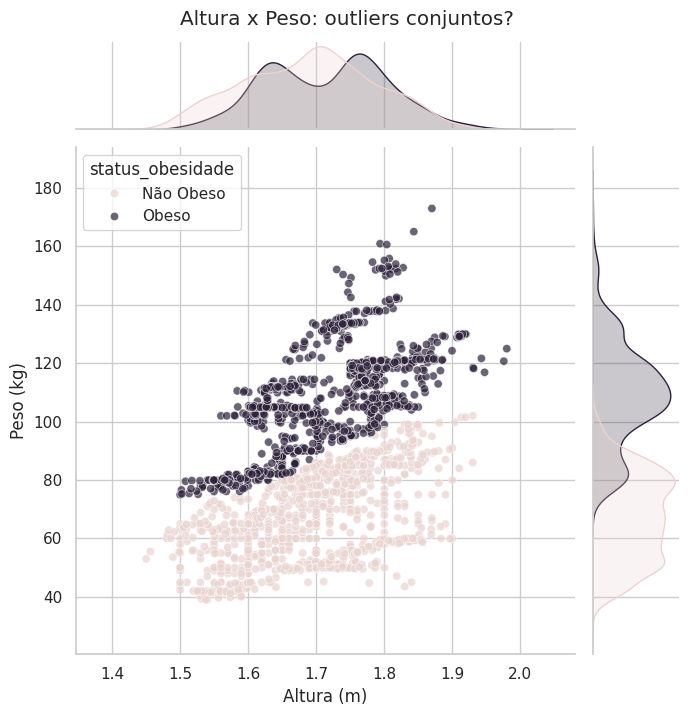

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Garantir que a coluna alvo exista na memória
if "status_obesidade" not in df.columns:
    classes_obesidade = ['Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']
    df['status_obesidade'] = np.where(df['NObeyesdad'].isin(classes_obesidade), 'Obeso', 'Não Obeso')

# 2. Plot conjunto de dispersão e distribuições marginais
g = sns.jointplot(
    data=df,
    x="Height",
    y="Weight",
    hue="status_obesidade",
    palette={"Não Obeso": COR_CONTEXTO, "Obeso": COR_DESTAQUE},
    alpha=0.7,
    height=7
)

g.fig.suptitle("Altura x Peso: outliers conjuntos?", y=1.02)
g.set_axis_labels("Altura (m)", "Peso (kg)")
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum de `trestbps` e `chol`?

Diferença na prática

Univariado: Olha só uma coluna por vez. Uma pessoa de 1,50 m parece normal no gráfico de altura.

Bivariado: Olha as duas coisas juntas. Se essa mesma pessoa de 1,50 m pesa 120 kg, a combinação salta aos olhos no gráfico porque foge completamente do padrão da maioria.

O que dá pra ver no gráfico (Altura x Peso)

Baixa estatura com peso alto: Há participantes entre 1,50 m e 1,60 m pesando mais de 115 kg. Isolados eles não parecem absurdos, mas juntos criam um IMC altíssimo (> 45) que se afasta da nuvem principal.

Alta estatura com peso baixo: O inverso também acontece em poucos casos, como pessoas de quase 1,90 m pesando cerca de 60 kg.

Densidade dos pontos: A maior parte dos dados fica bem agrupada e contínua porque a base usa dados aumentados (sintéticos), então não temos pontos soltos no "vazio" do gráfico.

O que isso significa

Não são erros de digitação, são casos reais de obesidade severa (Grau III).

Mostra que não dá pra classificar obesidade olhando só pro peso ou só pra altura de forma isolada; o que importa é a combinação das duas variáveis.

#### Análise Multivariada

##### Matriz de Correlação

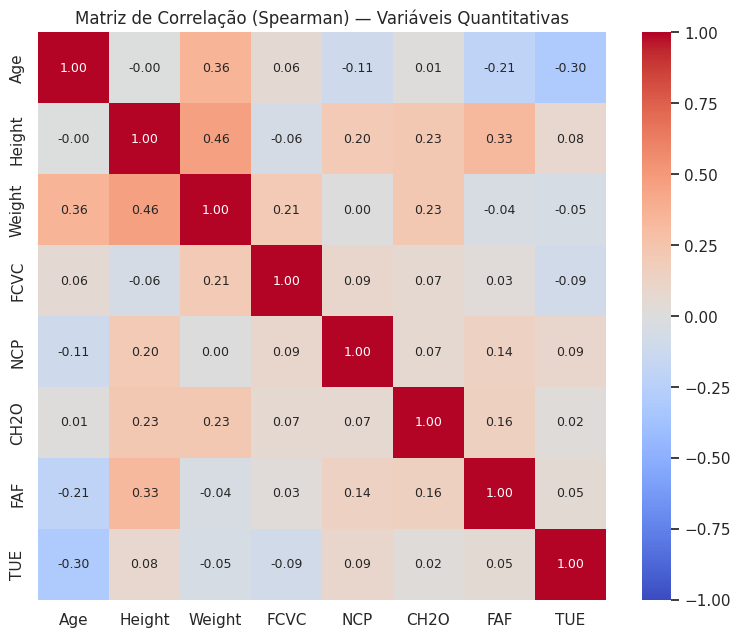

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Garante a lista das variáveis quantitativas do dataset de obesidade
VARS_QUANT = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']

# 2. Plota o heatmap completo de Spearman com formatação limpa
plt.figure(figsize=(8, 6.5))
sns.heatmap(
    df[VARS_QUANT].corr(method="spearman"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    annot_kws={"size": 9}
)

plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas", fontsize=12)
plt.tight_layout()
plt.show()


**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

Resposta direta: Não, nenhuma. Nenhuma correlação passa de 0,7, então não tem nenhuma coluna repetindo a informação de outra.

O que dá pra ver na prática

A mais forte é Altura x Peso (~0,46): Ainda assim é só moderada. Faz total sentido biológico: pessoas mais altas tendem a pesar mais, mas uma não entrega a outra de mão beijada.

Idade x Tempo de Tela (~ -0,30): É negativa e fraquinha/moderada. Basicamente mostra que a galera mais jovem passa um pouco mais de tempo no celular ou PC.

O resto é quase ruído (< 0,30): Hábitos como beber água, comer vegetais ou fazer exercício têm correlações bem baixas entre si.

##### Correlograma

Text(0.5, 1.02, 'Correlograma: Dispersão × Correlação')

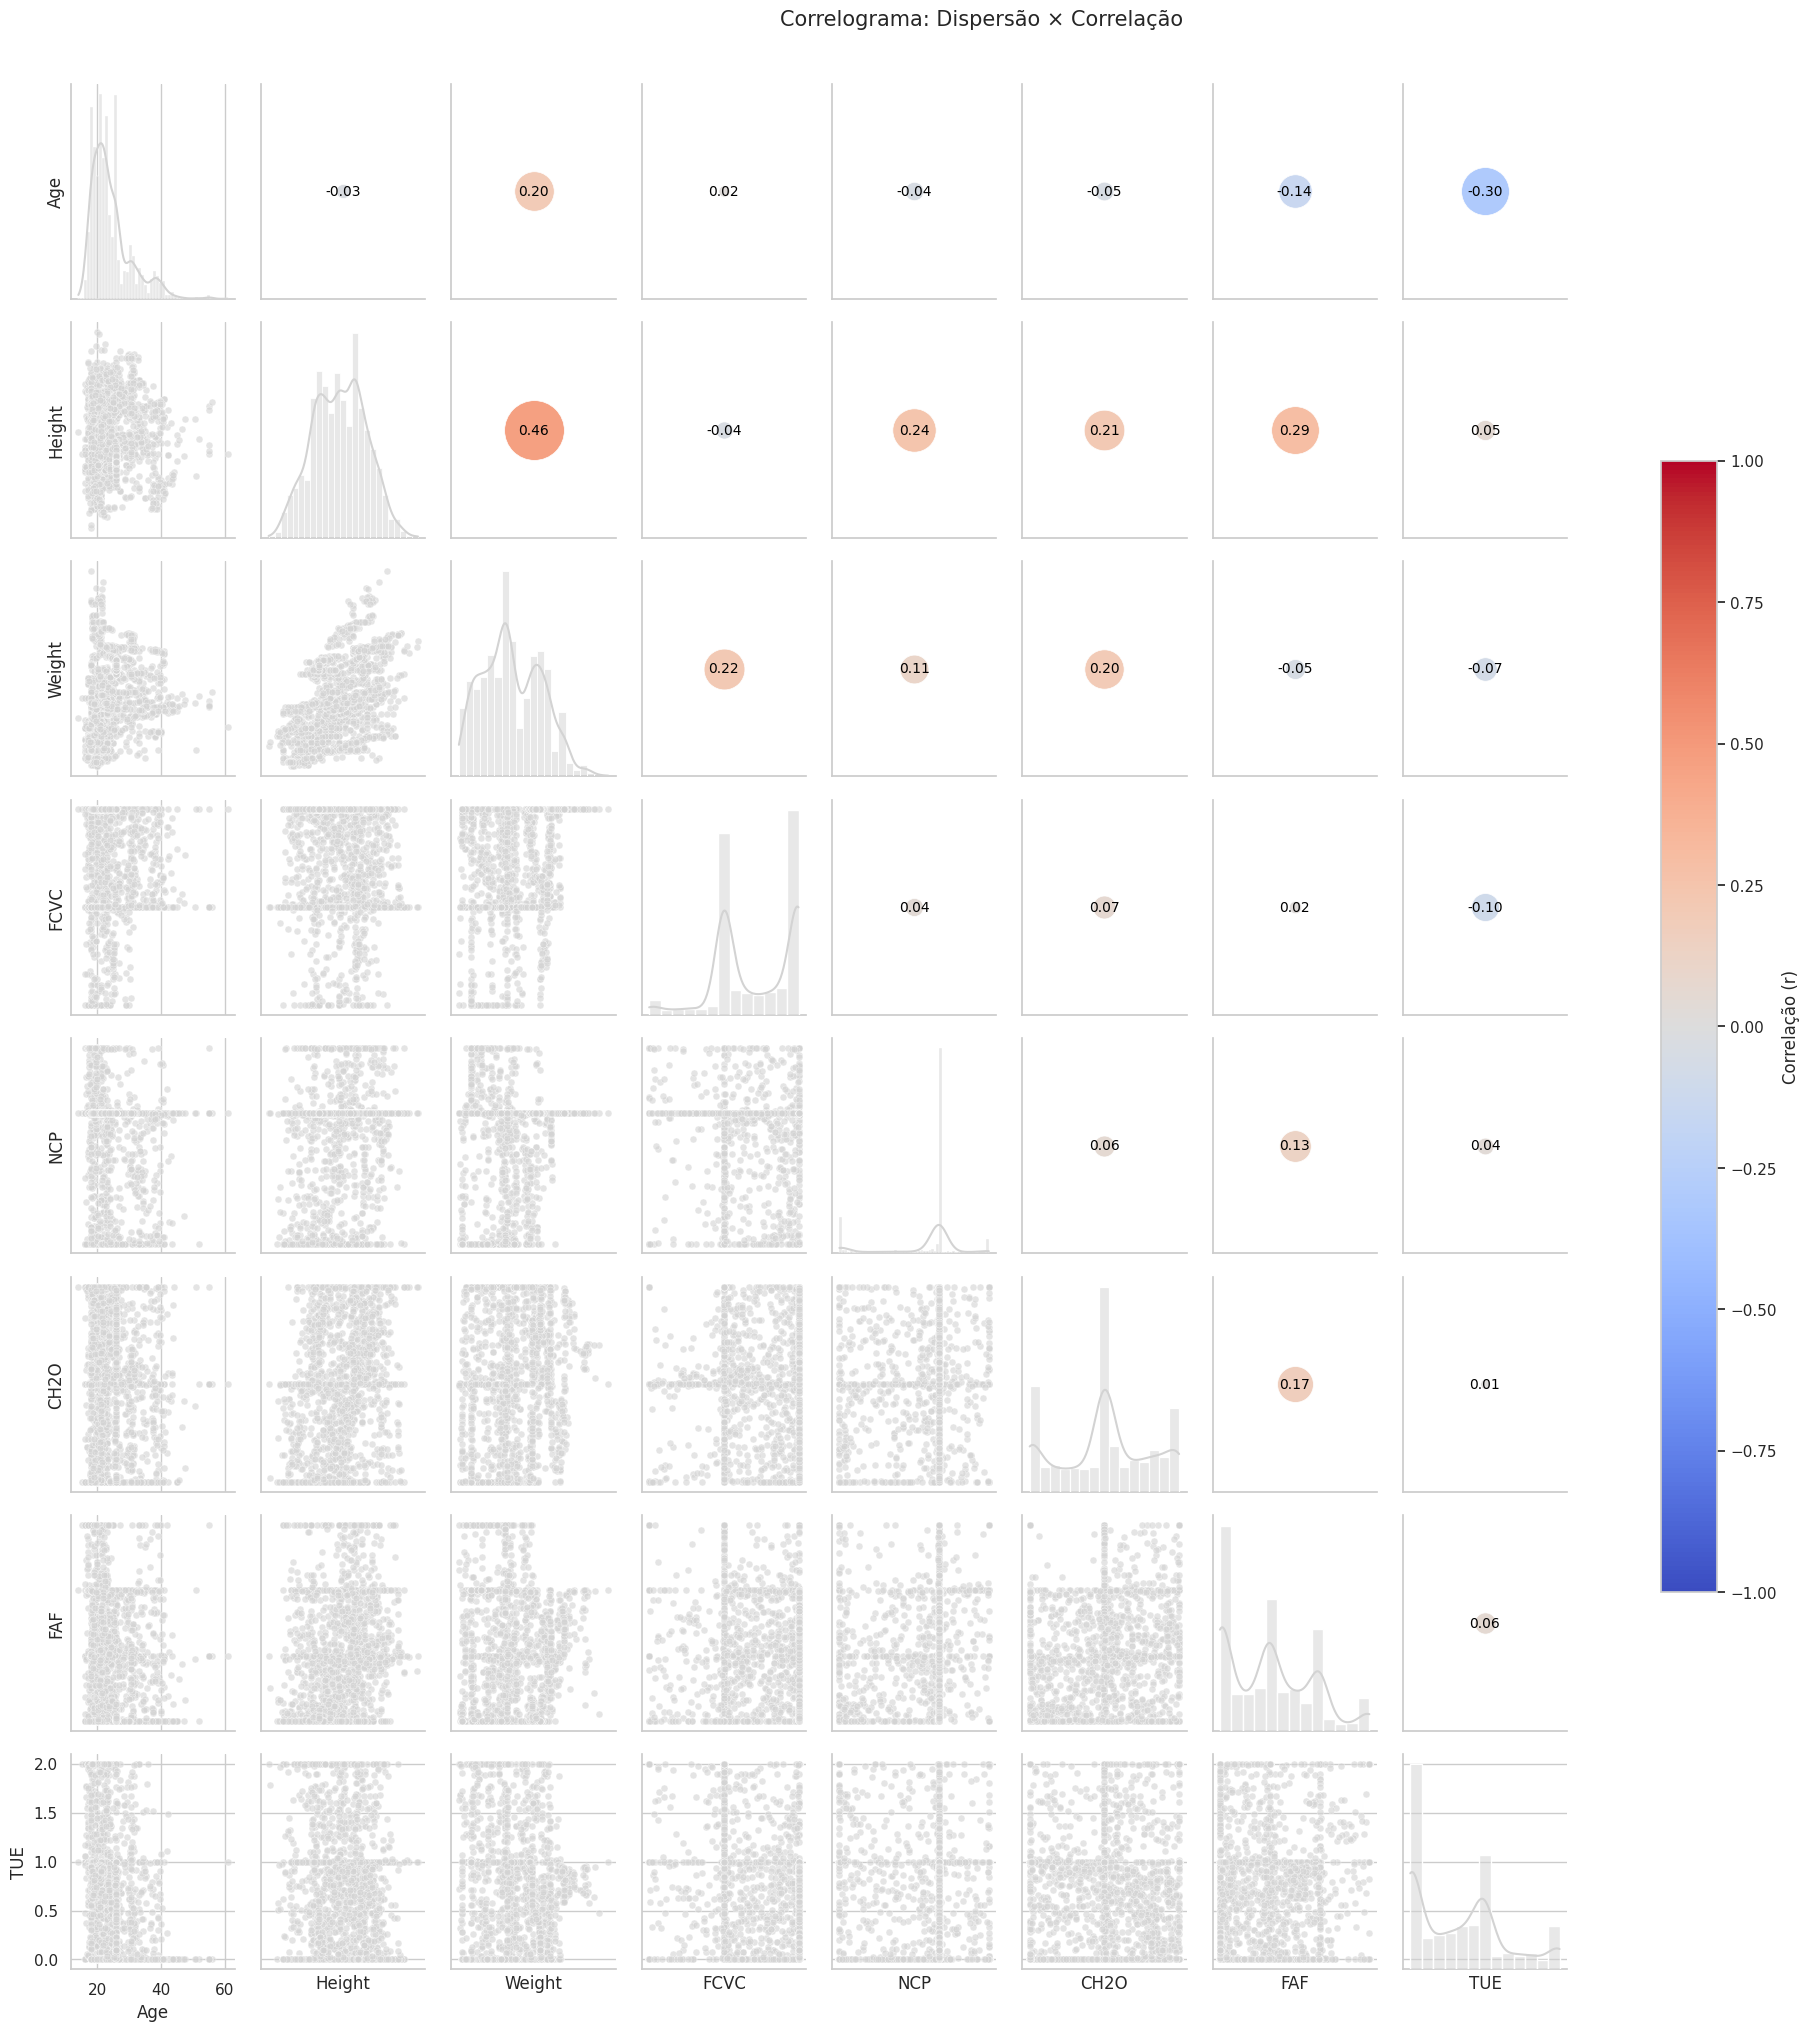

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)


## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.


